# CV ↔ İş İlanı Eşleştirme — Sızıntısız, İki Aşamalı (Two-Stage) SOTA Sistem
### Google Colab **A100** için uçtan uca eğitim, değerlendirme, ablation ve dışa aktarım

| | |
|---|---|
| **Görev** | Bir adayın CV'sine (sorgu) 3.000 ilanlık havuzdan en uygun ilanları sıralamak (Learning-to-Rank / Information Retrieval) |
| **Ground truth** | 4 kademeli alaka (0–3), ISCO-08 meslek kodu + uzmanlık + yaka + kıdem + lokasyon kurallarından **tüm** CV×ilan çiftleri için (tam yargı, pooling yok) |
| **Bölme** | Aday (CV) düzeyinde **ayrık** 70/15/15; aynı unvan / neredeyse-kopya CV'ler aynı bölümde; sentetik CV yalnız train'de; ilanların %10'u eğitimde **hiç görülmeyen** *cold* havuzu |
| **Aşama 1** | İnce ayarlı **BGE-M3** bi-encoder (Cached MNRL / InfoNCE + 4 tür zor negatif + CoSENT) ⊕ **BM25** → **RRF** ile Top-50 |
| **Aşama 2** | İnce ayarlı **bge-reranker-v2-m3** cross-encoder (LambdaLoss) → **LambdaMART** (LightGBM, `lambdarank`) |
| **Metrikler** | NDCG@10 (tam havuz IDCG), MRR@10, P@10, R@10/50/100, Top-1; %95 bootstrap GA, Fisher randomizasyon testi |

**Çalıştırma (5 dakikalık özet):** `Çalışma Zamanı → Çalışma zamanı türünü değiştir → A100 GPU` seçin, `data_bundle.zip`'i
yükleyin (ilk hücreler sorar) ve `Çalışma Zamanı → Tümünü çalıştır` deyin. A100-40GB'da toplam süre **tahminen** ≈ 1,5–2,5 saat (GPU'da ölçülmedi;
CPU kuru çalıştırması yalnız akışı doğrular). Drive bağlama izni bir kez sorulur.

```
               ┌─────────────── AŞAMA 1: ADAY ÜRETİMİ ───────────────┐   ┌──────── AŞAMA 2: YENİDEN SIRALAMA ────────┐
 CV (sorgu) ──►│ BGE-M3 bi-encoder (MNRL+HN) ─┐                       │   │ Cross-encoder (LambdaLoss) ─┐              │
               │                              ├─► RRF (k=60) ─► Top-50 ├──►│                             ├─► LambdaMART ├─► Top-10
               │ BM25 (Türkçe F5)  ───────────┘                       │   │ Metin-türevli öznitelikler ─┘  (lambdarank) │
               └──────────────────────────────────────────────────────┘   └──────────────────────────────────────────────┘
```

> **Sızıntı yasası:** Hiçbir model, adayın *altın* (gold) etiketlerini (Category, yaka, ISCO, kıdem) özellik olarak görmez.
> Sektör/yaka uyumu yalnızca **train bölümünde eğitilmiş** metin sınıflandırıcılarının olasılıklarıdır. `gold_*` sütunları
> yalnızca değerlendirmede kullanılır. `assert_no_gold_columns`, her öznitelik tablosunda etiket adlı sütun (gold_*, legacy_*,
> grade, label, …) olmadığını denetleyen bir **şema denetimidir**; tarafsız ada konmuş bir etiket değerini yakalayamaz.

## 0. Kurulum
Sürümler, bu notebook'un doğrulandığı sürümlere sabitlenmiştir. `torch`, `scikit-learn`, `pandas`, `matplotlib`, `seaborn`
için Colab'ın önceden kurulu (CUDA ile uyumlu) sürümleri kullanılır; böylece CUDA/torch çakışması olmaz.

In [1]:
import os, sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
DRY_RUN = os.environ.get("CV_DRY_RUN", "0") == "1"      # yerel CPU duman testi (küçük rastgele modeller)
PINNED = [
    "sentence-transformers==6.1.0", "transformers==5.17.0", "accelerate==1.15.0", "datasets==5.1.0",
    "rank_bm25==0.2.2", "lightgbm==4.7.0", "optuna==5.0.0", "faiss-cpu==1.15.1", "joblib", "tqdm",
]
if IN_COLAB or os.environ.get("CV_FORCE_INSTALL") == "1":
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINNED], check=True)
    print("Kurulum tamam.")
else:
    print("Colab dışı ortam: kurulum atlandı (gerekli paketlerin kurulu olduğu varsayılır).")

Colab dışı ortam: kurulum atlandı (gerekli paketlerin kurulu olduğu varsayılır).


In [2]:
import json, math, random, time, gc, re, zipfile, shutil, warnings, inspect, copy
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

import sentence_transformers, transformers, lightgbm as lgb, optuna, sklearn
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.training_args import BatchSamplers, MultiDatasetBatchSamplers
from sentence_transformers.sentence_transformer.losses import (
    CachedMultipleNegativesRankingLoss, MultipleNegativesRankingLoss, CoSENTLoss, CosineSimilarityLoss)
from sentence_transformers.sentence_transformer.evaluation import SentenceEvaluator
from sentence_transformers.cross_encoder import CrossEncoder, CrossEncoderTrainer, CrossEncoderTrainingArguments
from sentence_transformers.cross_encoder.losses import LambdaLoss
from datasets import Dataset
from transformers import EarlyStoppingCallback, TrainerCallback
try:
    from IPython.display import display
except ImportError:
    display = print
optuna.logging.set_verbosity(optuna.logging.WARNING)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMPERE = DEVICE == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8      # A100/L4/H100
BF16 = bool(AMPERE and torch.cuda.is_bf16_supported())      # bf16 yalnız Ampere+ (T4'te emülasyon olur)
FP16 = bool(DEVICE == "cuda" and not BF16)                  # T4/V100: fp16 karma hassasiyet
TF32 = bool(AMPERE)                                         # TF32 yalnız Ampere+ (T4/V100'de tf32=True hata verir)
if DEVICE == "cuda":
    if TF32:
        # A100: TF32 tensor çekirdekleri (fp32 doğruluğuna yakın, ~8x hızlı matmul)
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.set_float32_matmul_precision("high")
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory/1e9:.1f} GB | bf16={BF16} | tf32={TF32} | fp16={FP16}")
    if "A100" not in p.name:
        print("UYARI: A100 dışı GPU. CFG'de BI_BATCH / CE_BATCH değerlerini düşürmeniz gerekebilir.")
else:
    print("GPU yok -> CPU (yalnızca DRY_RUN için uygundur).")
EXPECTED = {"sentence-transformers": ("6.1.0", sentence_transformers.__version__), "transformers": ("5.17.0", transformers.__version__),
            "lightgbm": ("4.7.0", lgb.__version__)}
bad = {k: v for k, v in EXPECTED.items() if v[0] != v[1]}
if bad and not DRY_RUN:
    print("UYARI: Sabitlenmiş sürümlerden farklı paketler yüklü:", bad,
          "\n -> 'Çalışma zamanı > Oturumu yeniden başlat' yapıp notebook'u yeniden çalıştırın.")
print("torch", torch.__version__, "| sentence-transformers", sentence_transformers.__version__,
      "| transformers", transformers.__version__, "| lightgbm", lgb.__version__, "| optuna", optuna.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

/home/user/.venv-cv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU yok -> CPU (yalnızca DRY_RUN için uygundur).
torch 2.14.1+cu130 | sentence-transformers 6.1.0 | transformers 5.17.0 | lightgbm 4.7.0 | optuna 5.0.0


## 1. Yapılandırma
Tüm hiperparametreler tek yerde. `DRY_RUN=1` ortam değişkeni ile notebook, ağ erişimi olmayan bir CPU'da
küçük rastgele modellerle uçtan uca **duman testi** olarak çalışır (bu doğrulama deposunda yapılmıştır).

In [3]:
CFG = dict(
    SEED=42,
    # --- modeller
    BI_ENCODER_BASE="BAAI/bge-m3",                    # alternatif: "intfloat/multilingual-e5-large"
    CROSS_ENCODER_BASE="BAAI/bge-reranker-v2-m3",
    BASELINE_SMALL="intfloat/multilingual-e5-small",  # Baseline 2 ve 3 (eski projenin modeli)
    MAX_SEQ_LEN=512, CE_MAX_LEN=512, ENC_BATCH=128,
    # --- Aşama 1: bi-encoder
    BI_LOSS="cached_mnrl",          # 'cached_mnrl' (GradCache, büyük etkin batch) | 'mnrl'
    BI_USE_COSENT=True,             # kademeli (0-3) çiftlerle CoSENT çoklu-görev kaybı
    BI_EPOCHS=3, BI_BATCH=64, BI_MINI_BATCH=16, BI_LR=2e-5, BI_WARMUP=0.1, BI_WD=0.01,
    BI_SCALE=20.0,                  # MNRL ölçeği = 1/τ (τ=0.05)
    TUNE_TEMPERATURE=True, TEMP_GRID=[20.0, 50.0], TEMP_FRACTION=0.5,   # τ ∈ {0.05, 0.02}
    DENSE_MINED_NEG=True,           # base modelle zor negatif madenciliği (qrels ile yanlış-negatif filtresi)
    GRAD_CKPT=True,
    EVALS_PER_EPOCH=2, EARLY_STOP_PATIENCE=3,
    # --- hibrit getirim
    RRF_K=60, N_CANDIDATES=50,
    # --- Aşama 2a: cross-encoder
    CE_EPOCHS=2, CE_BATCH=8, CE_DOCS_PER_QUERY=16, CE_MINI_BATCH=32, CE_LR=1e-5, CE_TRAIN_QUERIES=None,
    # --- Aşama 2b: LambdaMART
    LTR_TRIALS=40, LTR_FOLDS=5, LTR_MAX_ROUNDS=2000,
    # --- Baseline 3 (eski yaklaşım: CosineSimilarityLoss, batch 8, 3 epoch)
    LEGACY_EPOCHS=3, LEGACY_BATCH=8,
    REL_THRESHOLD=2,                # binary metriklerde 'alakalı' = grade >= 2
    USE_SYNTHETIC=True,             # False: yalnız gerçek CV'lerle eğitim (sentetik veri ablation'ı için)
    USE_DRIVE=True,                 # Colab: Google Drive bağla (veri paketini oradan bul, sonuçları oraya yedekle)
    EXPORT_HALF=True,               # dışa aktarılan model ağırlıklarını fp16 kaydet (paket ~2 kat küçük)
    COSENT_PER_GRADE=1,
    WORK_DIR="/content" if IN_COLAB else os.path.abspath("."),
)
CFG["DATA_DIR"] = os.path.join(CFG["WORK_DIR"], "data_bundle")
CFG["OUT_DIR"] = os.path.join(CFG["WORK_DIR"], "outputs")
CFG["EXPORT_DIR"] = os.path.join(CFG["WORK_DIR"], "export_model_bundle")
CFG["FIG_DIR"] = os.path.join(CFG["OUT_DIR"], "figures")
if DRY_RUN:
    CFG.update(BI_EPOCHS=1, BI_BATCH=16, BI_MINI_BATCH=8, ENC_BATCH=64, TEMP_GRID=[20.0, 50.0], TEMP_FRACTION=0.5,
               CE_EPOCHS=1, CE_BATCH=4, CE_DOCS_PER_QUERY=6, CE_MINI_BATCH=12, LTR_TRIALS=3, LTR_FOLDS=3,
               LTR_MAX_ROUNDS=60, LEGACY_EPOCHS=1, MAX_SEQ_LEN=256, CE_MAX_LEN=256, EVALS_PER_EPOCH=1)
for d in (CFG["OUT_DIR"], CFG["FIG_DIR"]):
    os.makedirs(d, exist_ok=True)
set_seed(CFG["SEED"])
print(json.dumps({k: v for k, v in CFG.items()}, indent=1, ensure_ascii=False))

{
 "SEED": 42,
 "BI_ENCODER_BASE": "BAAI/bge-m3",
 "CROSS_ENCODER_BASE": "BAAI/bge-reranker-v2-m3",
 "BASELINE_SMALL": "intfloat/multilingual-e5-small",
 "MAX_SEQ_LEN": 256,
 "CE_MAX_LEN": 256,
 "ENC_BATCH": 64,
 "BI_LOSS": "cached_mnrl",
 "BI_USE_COSENT": true,
 "BI_EPOCHS": 1,
 "BI_BATCH": 16,
 "BI_MINI_BATCH": 8,
 "BI_LR": 2e-05,
 "BI_WARMUP": 0.1,
 "BI_WD": 0.01,
 "BI_SCALE": 20.0,
 "TUNE_TEMPERATURE": true,
 "TEMP_GRID": [
  20.0,
  50.0
 ],
 "TEMP_FRACTION": 0.5,
 "DENSE_MINED_NEG": true,
 "GRAD_CKPT": true,
 "EVALS_PER_EPOCH": 1,
 "EARLY_STOP_PATIENCE": 3,
 "RRF_K": 60,
 "N_CANDIDATES": 50,
 "CE_EPOCHS": 1,
 "CE_BATCH": 4,
 "CE_DOCS_PER_QUERY": 6,
 "CE_MINI_BATCH": 12,
 "CE_LR": 1e-05,
 "CE_TRAIN_QUERIES": null,
 "LTR_TRIALS": 3,
 "LTR_FOLDS": 3,
 "LTR_MAX_ROUNDS": 60,
 "LEGACY_EPOCHS": 1,
 "LEGACY_BATCH": 8,
 "REL_THRESHOLD": 2,
 "USE_SYNTHETIC": true,
 "USE_DRIVE": true,
 "EXPORT_HALF": true,
 "COSENT_PER_GRADE": 1,
 "WORK_DIR": "/home/user/umidovski/work/dry_run",
 "DATA_DIR"

## 2. Veri paketini yükleme (`data_bundle.zip`)
Sırasıyla şuralara bakılır: `CV_DATA_BUNDLE` ortam değişkeni, `/content/data_bundle.zip`, çalışma klasörü,
Google Drive (`MyDrive/data_bundle.zip`). Bulunamazsa Colab dosya yükleme penceresi açılır.

In [4]:
def locate_bundle():
    cands = [os.environ.get("CV_DATA_BUNDLE"), os.path.join(CFG["WORK_DIR"], "data_bundle.zip"),
             os.path.abspath("data_bundle.zip"), "/content/drive/MyDrive/data_bundle.zip"]
    for c in cands:
        if c and os.path.exists(c):
            return c
    if IN_COLAB:
        from google.colab import files
        print("data_bundle.zip dosyasını seçin ...")
        up = files.upload()
        for name in up:
            if name.endswith(".zip"):
                return os.path.abspath(name)
    raise FileNotFoundError("data_bundle.zip bulunamadı. CV_DATA_BUNDLE ile yol verin.")

DRIVE_DIR = None
if IN_COLAB and CFG["USE_DRIVE"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = "/content/drive/MyDrive/cv_ilan_sota"
        os.makedirs(DRIVE_DIR, exist_ok=True)
        print("Drive bağlandı; sonuçlar ayrıca", DRIVE_DIR, "klasörüne yedeklenecek.")
    except Exception as e:
        print("Drive bağlanmadı (sorun değil, yerel diskle devam):", e)
if not os.path.exists(os.path.join(CFG["DATA_DIR"], "metadata.json")):
    zp = locate_bundle()
    print("Açılıyor:", zp)
    with zipfile.ZipFile(zp) as z:
        z.extractall(CFG["WORK_DIR"])
sys.path.insert(0, CFG["DATA_DIR"])
import match_candidate_sota as core
importlib.reload(core)
META = json.load(open(os.path.join(CFG["DATA_DIR"], "metadata.json"), encoding="utf-8"))
print("Paket:", sorted(os.listdir(CFG["DATA_DIR"])))
print("Çekirdek modül sürümü:", core.__version__)

Açılıyor: /home/user/umidovski/data_bundle.zip
Paket: ['README.md', '__pycache__', 'clean_cvs.parquet', 'clean_jobs.parquet', 'legacy_train_pairs.parquet', 'match_candidate_sota.py', 'metadata.json', 'qrels_ground_truth.parquet', 'test_queries.parquet', 'train_queries.parquet', 'train_triplets.parquet', 'val_queries.parquet', 'val_triplets.parquet']
Çekirdek modül sürümü: 1.0.0


In [5]:
D = CFG["DATA_DIR"]
cvs = pd.read_parquet(f"{D}/clean_cvs.parquet")
jobs = pd.read_parquet(f"{D}/clean_jobs.parquet").reset_index(drop=True)
trip = pd.read_parquet(f"{D}/train_triplets.parquet")
vtrip = pd.read_parquet(f"{D}/val_triplets.parquet")
qrels_df = pd.read_parquet(f"{D}/qrels_ground_truth.parquet")
legacy_pairs = pd.read_parquet(f"{D}/legacy_train_pairs.parquet")
N_JOBS = len(jobs)
JIDX = {k: i for i, k in enumerate(jobs.job_key)}
CV = cvs.set_index("cv_id", drop=False)
COLD = (jobs.job_pool == "cold").to_numpy()
WARM = ~COLD

# qrels: {cv_id: {job_idx: grade}} (grade 0 örtük)
QRELS = defaultdict(dict)
for c, j, g in zip(qrels_df.cv_id.to_numpy(), qrels_df.job_key.map(JIDX).to_numpy(), qrels_df.grade.to_numpy()):
    QRELS[int(c)][int(j)] = int(g)

def grade(cid, j):
    return QRELS[int(cid)].get(int(j), 0)

# ---- SIZINTI KORUYUCULARI (çalışma zamanında yeniden doğrulama)
S = {s: set(cvs.cv_id[cvs.split == s]) for s in ("train", "val", "test")}
assert not (S["train"] & S["val"]) and not (S["train"] & S["test"]) and not (S["val"] & S["test"]), "split kesişimi!"
assert set(cvs.cv_id[cvs.source == "synthetic"]) <= S["train"], "sentetik CV train dışında!"
assert set(trip.anchor_cv_id) <= S["train"] and set(vtrip.anchor_cv_id) <= S["val"], "triplet anchor sızıntısı!"
cold_keys = set(jobs.job_key[COLD])
for c in ["positive_job_key", "neg_lexical_job_key", "neg_seniority_collar_job_key", "neg_bm25_job_key"]:
    assert not set(trip[c]) & cold_keys, f"cold ilan triplette: {c}"
assert set(legacy_pairs.cv_id) <= S["train"], "eski çiftlerde train dışı CV!"
print("Sızıntı koruyucuları: TAMAM")
print(cvs.groupby(["split", "source"]).size().unstack(fill_value=0))
print("İlan havuzu:", jobs.job_pool.value_counts().to_dict(), "| qrels satırı:", len(qrels_df),
      "| grade dağılımı:", qrels_df.grade.value_counts().sort_index().to_dict())
print("Alaka kuralları:")
for k, v in META["alaka_dereceleri"].items():
    print(" ", k, "→", v)

Sızıntı koruyucuları: TAMAM
source  real  synthetic
split                  
test     461          0
train   2125        710
val      457          0
İlan havuzu: {'warm': 2699, 'cold': 301} | qrels satırı: 608691 | grade dağılımı: {1: 471829, 2: 131751, 3: 5111}
Alaka kuralları:
  3 → Tam eslesme: ayni uzmanlik (occ_key) + yaka uyumu + |kidem farki| <= 1 + lokasyon uyumu (ayni sehir veya Remote)
  2 → Yuksek alaka: ayni ISCO-08 birim grubu (isco4) + yaka uyumu + |kidem farki| <= 2 (kidem/lokasyonda tolere edilebilir fark)
  1 → Kismi alaka: yaka uyumu + (ayni ana sektor VEYA ayni isco4 fakat kidem farki >= 3)
  0 → Alakasiz / uygunsuz: diger tum durumlar (farkli yaka, farkli sektor ve farkli meslek)


In [6]:
# Değerlendirme sorguları
rng = np.random.default_rng(CFG["SEED"])
if not CFG["USE_SYNTHETIC"]:
    trip = trip[trip.anchor_source != "synthetic"].reset_index(drop=True)
    print("USE_SYNTHETIC=False -> sentetik anchor'lar eğitimden çıkarıldı")
TRAIN_IDS = sorted(S["train"]); VAL_IDS = sorted(S["val"]); TEST_IDS = sorted(S["test"])
SHOWCASE = [c for c in META["vitrin_adaylari_test"] if c in S["test"]]
if DRY_RUN:   # duman testi için küçük alt örneklem (vitrin adayları her zaman dahil)
    VAL_IDS = sorted(rng.choice(VAL_IDS, 24, replace=False).tolist())
    TEST_IDS = sorted(set(rng.choice(TEST_IDS, 24, replace=False).tolist()) | set(SHOWCASE))
    keep = set(rng.choice(sorted(set(trip.anchor_cv_id)), 60, replace=False).tolist())
    trip = trip[trip.anchor_cv_id.isin(keep)].reset_index(drop=True)
    vtrip = vtrip[vtrip.anchor_cv_id.isin(VAL_IDS)].reset_index(drop=True)
    legacy_pairs = legacy_pairs.sample(min(400, len(legacy_pairs)), random_state=0).reset_index(drop=True)
    TRAIN_IDS = sorted(keep)
n_rel = {q: sum(1 for g in QRELS[q].values() if g >= CFG["REL_THRESHOLD"]) for q in TEST_IDS}
print(f"train anchor: {trip.anchor_cv_id.nunique()} | val sorgu: {len(VAL_IDS)} | test sorgu: {len(TEST_IDS)} "
      f"(alakalı ilanı olmayan test sorgusu: {sum(v == 0 for v in n_rel.values())})")
print("Vitrin (test) adayları:", {c: CV.loc[c, 'headline'] for c in SHOWCASE})

train anchor: 60 | val sorgu: 24 | test sorgu: 27 (alakalı ilanı olmayan test sorgusu: 1)
Vitrin (test) adayları: {20951: 'Gaziantep Baklava & Yufka Ustası', 10587: 'Flight Operations Dispatcher', 10511: 'Java Spring Boot Geliştirici', 21029: 'Java ve Spring Boot Yazılım Stajyeri'}


## 3. Değerlendirme altyapısı
* **NDCG@10**: üstel kazanç $2^{rel}-1$, logaritmik indirim; **IDCG, sorgunun tüm havuzdaki derecelerinden** hesaplanır
  (eski `test.py`'deki "yalnız dönen 10 sonuçtan IDCG" hatası yoktur).
* **MRR@10, P@10, R@k, Top-1**: alakalı = grade ≥ 2. `P@10_capped` = isabet / min(10, |alakalı|).
* Alakalı ilanı olmayan sorgular TREC geleneğiyle ortalamaya katılmaz (sayısı raporlanır).
* İstatistik: %95 bootstrap güven aralığı, iki yönlü **Fisher randomizasyon testi** (Smucker vd., 2007).

In [7]:
RESULTS = {}

def ranked_lists(Smat, qids, k=100, cols=None):
    cols = np.arange(Smat.shape[1]) if cols is None else np.asarray(cols)
    top = core.topk_indices(Smat, min(k, Smat.shape[1]))
    return {int(q): cols[top[i]].tolist() for i, q in enumerate(qids)}

def qrels_for(qids, cols=None):
    if cols is None:
        return {int(q): QRELS[int(q)] for q in qids}
    cs = set(int(c) for c in cols)
    return {int(q): {j: g for j, g in QRELS[int(q)].items() if j in cs} for q in qids}

def evaluate(ranked, name=None, cols=None, store=True):
    res = core.evaluate_rankings(ranked, qrels_for(list(ranked), cols), k=10, rel_threshold=CFG["REL_THRESHOLD"])
    if name and store:
        RESULTS[name] = res
    return res["summary"]

def eval_scores(Smat, qids, name=None, cols=None, store=True):
    return evaluate(ranked_lists(Smat, qids, cols=cols), name, cols, store)

def fmt(summary, keys=("NDCG@10", "MRR@10", "P@10", "P@10_capped", "R@10", "R@50", "Top1", "Top1_exact(grade3)")):
    return {k: round(100 * summary[k], 2) for k in keys if k in summary}

class LogCollector(TrainerCallback):
    # Trainer'ın her log kaydını (train loss, eval loss, eval metrikleri) toplar
    def __init__(self): self.rows = []
    def on_log(self, args, state, control, logs=None, **kw):
        if logs:
            row = {"step": state.global_step, "epoch": state.epoch}; row.update(logs); self.rows.append(row)

def plot_logs(rows, title, fname):
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    if "loss" in df:
        d = df.dropna(subset=["loss"]); ax[0].plot(d.step, d.loss, lw=1, label="train loss")
    if "eval_loss" in df:
        d = df.dropna(subset=["eval_loss"]); ax[0].plot(d.step, d.eval_loss, "o-", label="val loss")
    ax[0].set_title("Kayıp (loss)"); ax[0].set_xlabel("adım"); ax[0].legend()
    mcols = [c for c in df.columns if c.startswith("eval_") and any(m in c for m in ("ndcg", "mrr", "p@10", "r@10", "top1"))]
    for c in mcols:
        d = df.dropna(subset=[c]); ax[1].plot(d.step, d[c], "o-", label=c.replace("eval_", ""))
    ax[1].set_title("Doğrulama metrikleri"); ax[1].set_xlabel("adım"); ax[1].legend(fontsize=7)
    if "learning_rate" in df:
        d = df.dropna(subset=["learning_rate"]); ax[2].plot(d.step, d.learning_rate)
    ax[2].set_title("Öğrenme oranı (cosine + warmup)")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(os.path.join(CFG["FIG_DIR"], fname), dpi=120); plt.show()
    return df

def free_mem():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

### 3.1 Duman testi için küçük yerel modeller (yalnız `DRY_RUN`)
Ağ erişimi olmayan doğrulama ortamında Hugging Face modelleri indirilemez; bu hücre korpus üzerinde bir WordPiece
sözlüğü eğitip **rastgele başlatılmış** 2 katmanlı minik BERT'ler üretir. Colab'da bu hücre hiçbir şey yapmaz.

In [8]:
if DRY_RUN:
    from tokenizers import BertWordPieceTokenizer
    from transformers import BertConfig, BertModel, BertForSequenceClassification, BertTokenizerFast
    tiny = os.path.join(CFG["OUT_DIR"], "tiny_models")
    os.makedirs(tiny, exist_ok=True)
    corpus = list(jobs.job_struct.sample(800, random_state=0)) + list(cvs.cv_struct.sample(800, random_state=0))
    wp = BertWordPieceTokenizer(lowercase=True, strip_accents=False)
    wp.train_from_iterator(corpus, vocab_size=4000, min_frequency=2)
    for name, cls in (("bi", BertModel), ("ce", BertForSequenceClassification), ("small", BertModel)):
        p = os.path.join(tiny, name); os.makedirs(p, exist_ok=True); wp.save_model(p)
        tok = BertTokenizerFast(vocab_file=os.path.join(p, "vocab.txt"), do_lower_case=True)
        cfg = BertConfig(vocab_size=tok.vocab_size, hidden_size=48, num_hidden_layers=2, num_attention_heads=2,
                         intermediate_size=96, max_position_embeddings=512, num_labels=1)
        torch.manual_seed(0); cls(cfg).save_pretrained(p); tok.save_pretrained(p)
    CFG.update(BI_ENCODER_BASE=os.path.join(tiny, "bi"), CROSS_ENCODER_BASE=os.path.join(tiny, "ce"),
               BASELINE_SMALL=os.path.join(tiny, "small"))
    print("DRY_RUN modelleri:", CFG["BI_ENCODER_BASE"], CFG["CROSS_ENCODER_BASE"], CFG["BASELINE_SMALL"])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 468.06it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 182.12it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 848.53it/s]

DRY_RUN modelleri: /home/user/umidovski/work/dry_run/outputs/tiny_models/bi /home/user/umidovski/work/dry_run/outputs/tiny_models/ce /home/user/umidovski/work/dry_run/outputs/tiny_models/small


In [9]:
def prefixes(model_name):
    # E5 ailesi 'query: ' / 'passage: ' önekleriyle eğitilmiştir (Wang vd., 2022); BGE-M3 önek istemez.
    n = str(model_name).lower()
    if "e5" in n and "instruct" in n:
        return "Instruct: Given a candidate CV, retrieve matching job postings\nQuery: ", ""
    if "e5" in n:
        return "query: ", "passage: "
    return "", ""

def load_st(name, max_len=None):
    m = SentenceTransformer(name, device=DEVICE)
    m.max_seq_length = max_len or CFG["MAX_SEQ_LEN"]
    return m

@torch.no_grad()
def encode(model, texts, bs=None):
    # autocast YOK: fp32 (A100'de TF32) -> çıkarımdaki SOTAMatcher ile aynı sayısal hassasiyet (öznitelik paritesi)
    bs = bs or CFG["ENC_BATCH"]
    e = model.encode(list(texts), batch_size=bs, normalize_embeddings=True, convert_to_numpy=True,
                     show_progress_bar=len(texts) > 1000)
    return np.asarray(e, dtype=np.float32)

WARM_COLS = np.where(~(jobs.job_pool == "cold").to_numpy())[0]   # model seçimi yalnız WARM ilanlarla yapılır

def cv_texts(ids, prefix=""):
    return [prefix + CV.loc[int(i), "cv_struct"] for i in ids]

def job_texts(prefix=""):
    return [prefix + t for t in jobs.job_struct]

def drop_amp_wrapper(m):
    # bf16/fp16 eğitimde accelerate model.forward'ı autocast+fp32 sarmalayıcısıyla değiştirir ve train() sonrası GERİ
    # ALMAZ; sonraki encode()/predict() çağrıları bf16 autocast altında koşar. Sarmalayıcı kaldırılır -> fp32/TF32.
    for mod in [m] + list(m.modules()):
        mod.__dict__.pop("forward", None); mod.__dict__.pop("_original_forward", None)
    return m

def enable_grad_ckpt(model):
    # ST 6.1 + transformers 5.x'te TrainingArguments(gradient_checkpointing=True) imza uyumsuzluğu verir;
    # bu yüzden gradient checkpointing doğrudan alttaki HF modeline uygulanır (use_reentrant=False).
    hf = model[0].auto_model
    hf.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    if hasattr(hf, "config"): hf.config.use_cache = False

## 4. Baseline 1 — Leksikal BM25 (Robertson & Zaragoza, 2009)
Türkçe için F5 kök kırpma (Can vd., 2008). Kendi vektörize BM25'imizin `rank_bm25.BM25Okapi` ile **birebir aynı**
skorları ürettiği önce doğrulanır.

In [10]:
from rank_bm25 import BM25Okapi
job_tokens = [core.tokenize(t) for t in jobs.job_struct]
BM25 = core.SparseBM25(job_tokens)
ref = BM25Okapi(job_tokens)
for q in TEST_IDS[:3]:
    qt = core.tokenize(CV.loc[q, "cv_struct"])
    assert np.allclose(BM25.scores([qt])[0], ref.get_scores(qt), rtol=1e-4, atol=1e-4), "BM25 paritesi bozuk"
print("BM25 paritesi (rank_bm25 ile): TAMAM")

def bm25_matrix(ids):
    return BM25.scores([core.tokenize(CV.loc[int(i), "cv_struct"]) for i in ids])

S_BM25 = {"val": bm25_matrix(VAL_IDS), "test": bm25_matrix(TEST_IDS)}
print("Baseline 1 (BM25):", fmt(eval_scores(S_BM25["test"], TEST_IDS, "B1: BM25")))

BM25 paritesi (rank_bm25 ile): TAMAM
Baseline 1 (BM25): {'NDCG@10': 57.3, 'MRR@10': 84.94, 'P@10': 51.15, 'P@10_capped': 58.44, 'R@10': 26.32, 'R@50': 45.72, 'Top1': 76.92, 'Top1_exact(grade3)': 11.54}


## 5. Baseline 2 — Sıfır-atış (zero-shot) `multilingual-e5-small`
Eğitimsiz ham model; aynı yapılandırılmış metinler, E5 önekleri.

In [11]:
small = load_st(CFG["BASELINE_SMALL"])
qp, dp = prefixes(CFG["BASELINE_SMALL"])
E_small_jobs = encode(small, job_texts(dp))
E_small_test = encode(small, cv_texts(TEST_IDS, qp))
S_ZS_SMALL = E_small_test @ E_small_jobs.T
print("Baseline 2 (zero-shot e5-small):", fmt(eval_scores(S_ZS_SMALL, TEST_IDS, "B2: Zero-shot e5-small")))
del small; free_mem()

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 3602.56it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   2%|▏         | 1/47 [00:00<00:04,  9.52it/s]

Batches:   6%|▋         | 3/47 [00:00<00:03, 14.06it/s]

...

Batches:  81%|████████  | 38/47 [00:02<00:00, 18.16it/s]

Batches:  87%|████████▋ | 41/47 [00:02<00:00, 20.24it/s]

Batches:  94%|█████████▎| 44/47 [00:02<00:00, 22.58it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 17.13it/s]

Baseline 2 (zero-shot e5-small): {'NDCG@10': 3.04, 'MRR@10': 6.16, 'P@10': 2.69, 'P@10_capped': 2.69, 'R@10': 0.25, 'R@50': 2.16, 'Top1': 0.0, 'Top1_exact(grade3)': 0.0}


## 6. Baseline 3 — Eski yaklaşım: `multilingual-e5-small` + `CosineSimilarityLoss` (sızıntısız testte gerçek performans)
Eski `sbertmodel.py` birebir yeniden üretilir (aynı metin biçimi, `query:`/`passage:`, batch 8, 3 epoch, %10 ısınma,
CosineSimilarityLoss). **Fark:** eğitim çiftleri yalnızca yeni *train* bölümündeki CV'lerden gelir (eski `train.csv`
satırlarından val/test CV'lerine ait olanlar çıkarılmıştır). Çıkarım `test.py`'deki biçimle yapılır.

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 3445.63it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.608218


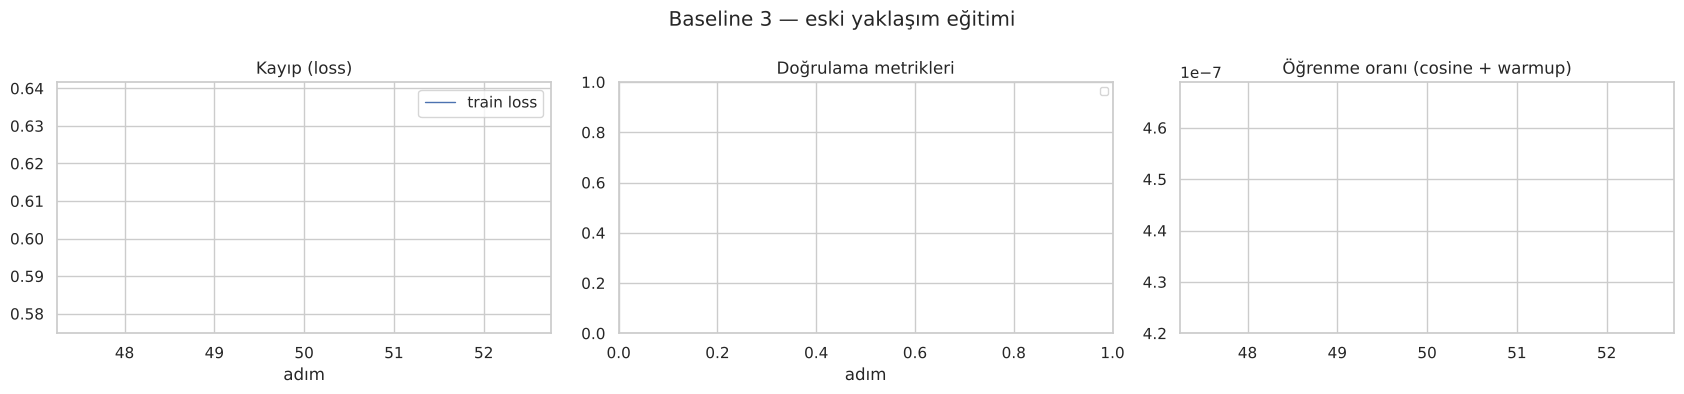

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   4%|▍         | 2/47 [00:00<00:03, 14.81it/s]

Batches:   9%|▊         | 4/47 [00:00<00:02, 15.32it/s]

Batches:  13%|█▎        | 6/47 [00:00<00:02, 15.31it/s]

Batches:  17%|█▋        | 8/47 [00:00<00:02, 15.25it/s]

...

Batches:  81%|████████  | 38/47 [00:02<00:00, 23.63it/s]

Batches:  87%|████████▋ | 41/47 [00:02<00:00, 24.24it/s]

Batches:  96%|█████████▌| 45/47 [00:02<00:00, 28.36it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 20.11it/s]

Baseline 3 (eski yaklaşım, ham skor): {'NDCG@10': 1.81, 'MRR@10': 1.36, 'P@10': 1.15, 'P@10_capped': 1.15, 'R@10': 0.07, 'R@50': 1.51, 'Top1': 0.0, 'Top1_exact(grade3)': 0.0}


In [12]:
def legacy_clean(t):
    t = str(t).replace("\n", " "); t = re.sub(r"(.)\1{2,}", r"\1", t); return re.sub(r"\s+", " ", t).strip()

set_seed(CFG["SEED"])
legacy_model = load_st(CFG["BASELINE_SMALL"], 512 if not DRY_RUN else CFG["MAX_SEQ_LEN"])
lp = legacy_pairs.dropna(subset=["job_key"])
ds_legacy = Dataset.from_dict({
    "sentence1": ["query: " + legacy_clean(CV.loc[c, "cv_text"]) for c in lp.cv_id],
    "sentence2": ["passage: " + legacy_clean(jobs.legacy_train_text.iloc[JIDX[k]]) for k in lp.job_key],
    "score": lp.label.astype(float).tolist(),
})
legacy_logs = LogCollector()
largs = SentenceTransformerTrainingArguments(
    output_dir=os.path.join(CFG["OUT_DIR"], "legacy_ckpt"), num_train_epochs=CFG["LEGACY_EPOCHS"],
    per_device_train_batch_size=CFG["LEGACY_BATCH"], learning_rate=2e-5, warmup_steps=0.1, lr_scheduler_type="linear",
    bf16=BF16, fp16=FP16, logging_steps=50, save_strategy="no", report_to="none", seed=CFG["SEED"])
SentenceTransformerTrainer(model=legacy_model, args=largs, train_dataset=ds_legacy,
                           loss=CosineSimilarityLoss(legacy_model), callbacks=[legacy_logs]).train()
drop_amp_wrapper(legacy_model)
plot_logs(legacy_logs.rows, "Baseline 3 — eski yaklaşım eğitimi", "b3_training.png")
# test.py çıkarım biçimi
E_leg_jobs = encode(legacy_model, ["passage: " + legacy_clean(t) for t in jobs.legacy_infer_text])
E_leg_test = encode(legacy_model, ["query: " + legacy_clean(CV.loc[q, "cv_text"]) for q in TEST_IDS])
S_LEGACY = E_leg_test @ E_leg_jobs.T
print("Baseline 3 (eski yaklaşım, ham skor):", fmt(eval_scores(S_LEGACY, TEST_IDS, "B3: Eski (e5-small + CosineSimLoss)")))

### 6.1 Sızıntı gösterimi: eski çarpanlar + eski metrik
Eski sistemin `Nihai Skor = Ham × Yaka × Kıdem × Lokasyon × Sektör` formülü, adayın **altın** `Category` ve
`collar` alanlarını kullanır; eski `test.py` ise başarıyı "aynı sektör mü?" diye ölçer. Aşağıda aynı modelin skorları
(1) eski metrikle ve (2) sızıntısız kademeli qrels ile ölçülür. Bu satırlar **geçersiz (sızıntılı)** olarak işaretlidir ve
ana ablation tablosuna girmez.

In [13]:
def legacy_multipliers(qids, ind_pen=0.85):
    # match_candidate.py'deki çarpanların birebir vektörize hali (altın Category/collar kullanır -> SIZINTILI)
    LEVEL = {'INTERN':1,'STUDENT':1,'TRAINEE':1,'ENTRY_LEVEL':2,'NEW_GRADUATE':2,'ASSISTANT':2,'ASSISTANT_SPECIALIST':2,
             'JUNIOR':2,'MID_LEVEL':3,'SPECIALIST':3,'SENIOR':4,'SENIOR_SPECIALIST':4,'TEAM_LEAD':4,'MANAGER':5,
             'EXECUTIVE':5,'DIRECTOR':5}
    jl = np.array([LEVEL.get(str(x).upper(), 0) for x in jobs.position_level])
    jcol = jobs.legacy_collar.to_numpy(dtype=object); jcity = jobs.legacy_city.to_numpy(dtype=object)
    jrem = jobs.is_remote.to_numpy(dtype=bool); jind = jobs.industry.to_numpy(dtype=object)
    M = np.zeros((len(qids), N_JOBS), dtype=np.float32)
    for i, q in enumerate(qids):
        r = CV.loc[q]
        col = (jcol == r.legacy_collar).astype(float)
        cl = LEVEL.get(str(r.legacy_seniority).upper(), 3)
        diff = np.abs(cl - jl); sen = np.where((jl == 0) | (diff <= 1), 1.0, 0.95 ** (diff - 1))
        same = np.array([bool(r.legacy_city) and r.legacy_city != "UNSPECIFIED" and bool(c) and (r.legacy_city in c or c in r.legacy_city) for c in jcity])
        loc = np.where(jrem | same, 1.0, 0.85 if r.legacy_collar == "BLUE" else 0.95)
        ind = np.where(jind == r.gold_industry, 1.0, ind_pen)        # <-- ALTIN ETİKET
        M[i] = col * sen * loc * ind
    return M

def old_metric(Smat, qids):
    # eski test.py: rel = 2 if aynı sektör; NDCG'de IDCG yalnız dönen 10 sonuçtan (yerel)
    top = core.topk_indices(Smat, 10); out = defaultdict(list)
    for i, q in enumerate(qids):
        rel = [2 if jobs.industry.iloc[j] == CV.loc[q, "gold_industry"] else 0 for j in top[i]]
        dcg_ = sum((2 ** r - 1) / math.log2(k + 2) for k, r in enumerate(rel))
        idcg = sum((2 ** r - 1) / math.log2(k + 2) for k, r in enumerate(sorted(rel, reverse=True)))
        out["P@10(sektör)"].append(np.mean([r > 0 for r in rel])); out["Top1(sektör)"].append(rel[0] > 0)
        out["NDCG@10(yerel IDCG)"].append(dcg_ / idcg if idcg else 0.0)
    return {k: round(100 * float(np.mean(v)), 2) for k, v in out.items()}

S_LEGACY_LEAKY = S_LEGACY * legacy_multipliers(TEST_IDS)
leak_tbl = pd.DataFrame({
    "B3 ham": {**old_metric(S_LEGACY, TEST_IDS), **fmt(eval_scores(S_LEGACY, TEST_IDS, store=False), ("NDCG@10", "P@10", "Top1"))},
    "B3 + eski çarpanlar (SIZINTILI)": {**old_metric(S_LEGACY_LEAKY, TEST_IDS), **fmt(eval_scores(S_LEGACY_LEAKY, TEST_IDS, store=False), ("NDCG@10", "P@10", "Top1"))},
    "Rastgele skor + eski çarpanlar (SIZINTILI)": {**old_metric(rng.uniform(.7, .9, S_LEGACY.shape) * legacy_multipliers(TEST_IDS), TEST_IDS)},
}).T
print("Sol 3 sütun = ESKİ metrik (döngüsel), sağ 3 sütun = sızıntısız kademeli qrels")
display(leak_tbl)
del legacy_model; free_mem()

Sol 3 sütun = ESKİ metrik (döngüsel), sağ 3 sütun = sızıntısız kademeli qrels


,P@10(sektör),Top1(sektör),NDCG@10(yerel IDCG),NDCG@10,P@10,Top1
B3 ham,7.04,3.7,17.56,1.81,1.15,0.00
B3 + eski çarpanlar (SIZINTILI),90.00,96.3,95.84,39.14,19.23,19.23
Rastgele skor + eski çarpanlar (SIZINTILI),87.78,96.3,95.31,NaN,NaN,NaN


## 7. Aşama 1 — Bi-encoder ince ayarı (BGE-M3, InfoNCE/MNRL + zor negatifler)
**Kayıp:** $\mathcal{L} = -\log \frac{e^{s(q,d^+)/\tau}}{e^{s(q,d^+)/\tau} + \sum_{d^-\in \mathcal{B}\cup \mathcal{H}} e^{s(q,d^-)/\tau}}$
(van den Oord vd., 2018; Henderson vd., 2017; Karpukhin vd., 2020). $\mathcal{B}$: batch-içi negatifler,
$\mathcal{H}$: her satırdaki 4 zor negatif — (i) leksikal tuzak, (ii) kıdem/yaka tuzağı, (iii) BM25, (iv) base modelle
**qrels-filtreli** yoğun madencilik (ANCE/RocketQA). Tam yargı sayesinde kural tabanlı qrels'e göre yanlış negatif
yoktur; yine de en benzer grade-0 ilanların bir kısmı yakın-alakalı olabilir (aşağıdaki tanı hücresi). **GradCache**
(Cached MNRL, Gao vd., 2021) ile A100'de büyük etkin batch. Ek olarak kademeli çiftlerde **CoSENT** (Su, 2022).

In [14]:
set_seed(CFG["SEED"])
QP, DP = prefixes(CFG["BI_ENCODER_BASE"])
base = load_st(CFG["BI_ENCODER_BASE"])
E_base_jobs = encode(base, job_texts(DP))

# Referans: base (zero-shot) BGE-M3
E_base_test = encode(base, cv_texts(TEST_IDS, QP))
print("Zero-shot base bi-encoder:", fmt(eval_scores(E_base_test @ E_base_jobs.T, TEST_IDS, "Ref: Zero-shot base bi-encoder")))

# (iv) Yoğun zor negatif madenciliği: base modelin üst sıralarına koyduğu grade-0 WARM ilanlar
anchors = sorted(set(trip.anchor_cv_id))
neg_dense = {}
if CFG["DENSE_MINED_NEG"]:
    E_anc = encode(base, cv_texts(anchors, QP))
    Sa = E_anc @ E_base_jobs.T
    Sa[:, COLD] = -np.inf
    top = core.topk_indices(Sa, 40)
    for i, a in enumerate(anchors):
        neg_dense[a] = [int(j) for j in top[i] if grade(a, j) == 0][:10]
del base; free_mem()

def build_mnrl_rows(tdf, neg_store=None):
    rows = defaultdict(list)
    seen = Counter()
    for r in tdf.itertuples():
        negs = [JIDX[r.neg_lexical_job_key], JIDX[r.neg_seniority_collar_job_key], JIDX[r.neg_bm25_job_key]]
        if CFG["DENSE_MINED_NEG"]:
            pool = [j for j in neg_dense.get(r.anchor_cv_id, []) if j not in negs]
            k = seen[r.anchor_cv_id]; seen[r.anchor_cv_id] += 1
            negs.append(pool[k % len(pool)] if pool else negs[-1])
        if neg_store is not None: neg_store.append(list(negs))
        rows["anchor"].append(QP + CV.loc[r.anchor_cv_id, "cv_struct"])
        rows["positive"].append(DP + jobs.job_struct.iloc[JIDX[r.positive_job_key]])
        for n, j in enumerate(negs, 1):
            rows[f"negative_{n}"].append(DP + jobs.job_struct.iloc[j])
    return Dataset.from_dict(dict(rows))

def build_cosent_rows(anchor_ids, per_grade=2, seed=0):
    r_ = np.random.default_rng(seed); s1, s2, sc = [], [], []
    for a in anchor_ids:
        by_g = defaultdict(list)
        for j, g in QRELS[a].items():
            if WARM[j]: by_g[g].append(j)
        hard0 = [j for j in neg_dense.get(a, []) if WARM[j]][:per_grade]
        if not hard0:
            hard0 = r_.choice(np.where(WARM)[0], per_grade, replace=False).tolist()
        by_g[0] = hard0
        for g, js in by_g.items():
            for j in r_.permutation(js)[:per_grade]:
                s1.append(QP + CV.loc[a, "cv_struct"]); s2.append(DP + jobs.job_struct.iloc[int(j)]); sc.append(g / 3.0)
    return Dataset.from_dict({"sentence1": s1, "sentence2": s2, "score": sc})

TRAIN_NEG_IDX = []
DS_TRAIN = build_mnrl_rows(trip, neg_store=TRAIN_NEG_IDX)
DS_VAL = build_mnrl_rows(vtrip) if len(vtrip) else None
DS_COSENT = build_cosent_rows(anchors, per_grade=CFG["COSENT_PER_GRADE"]) if CFG["BI_USE_COSENT"] else None
print("MNRL satırı:", len(DS_TRAIN), "| sütunlar:", DS_TRAIN.column_names, "| CoSENT çifti:", len(DS_COSENT) if DS_COSENT else 0)

# Tanı: rastgele batch'lerde batch-içi YANLIŞ negatif oranı. MNRL'de her anchor için paydada batch'teki TÜM
# pozitifler VE TÜM satırların zor negatifleri bulunur; bunlardan biri bu anchor için grade>=2 ise yanlış negatiftir.
pos_idx = [JIDX[k] for k in trip.positive_job_key]; anc = trip.anchor_cv_id.tolist()
B = CFG["BI_BATCH"]; cnt = Counter()
for _ in range(50):
    b = rng.choice(len(anc), min(B, len(anc)), replace=False)
    for x in b:
        for y in b:
            if x != y and pos_idx[y] != pos_idx[x]:
                g_ = grade(anc[x], pos_idx[y]); cnt["pos_tot"] += 1; cnt["pos_fn"] += g_ >= 2
            for j in TRAIN_NEG_IDX[y]:
                if j == pos_idx[x]: continue
                g_ = grade(anc[x], j); key = "own" if y == x else "oth"
                cnt[key + "_tot"] += 1; cnt[key + "_fn"] += g_ >= 2
pct = lambda a, b: 100 * cnt[a] / max(1, cnt[b])
print("Batch-içi yanlış-negatif oranı (rastgele batch'lerle tahmin, grade>=2):")
print(f"  başka satırların pozitifleri : %{pct('pos_fn', 'pos_tot'):.2f}  ({cnt['pos_fn']}/{cnt['pos_tot']})")
print(f"  başka satırların zor negatifleri: %{pct('oth_fn', 'oth_tot'):.2f}  ({cnt['oth_fn']}/{cnt['oth_tot']})")
print(f"  kendi zor negatifleri (qrels ile filtreli): %{pct('own_fn', 'own_tot'):.2f}  ({cnt['own_fn']}/{cnt['own_tot']})")
fn_all = cnt["pos_fn"] + cnt["oth_fn"] + cnt["own_fn"]; tot_all = cnt["pos_tot"] + cnt["oth_tot"] + cnt["own_tot"]
print(f"  toplam                      : %{100 * fn_all / max(1, tot_all):.2f}  (NO_DUPLICATES örnekleyici aynı metni engeller)")

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 3889.89it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   4%|▍         | 2/47 [00:00<00:03, 12.38it/s]

Batches:   9%|▊         | 4/47 [00:00<00:03, 13.51it/s]

...

Batches:  91%|█████████▏| 43/47 [00:02<00:00, 19.87it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 24.00it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 16.97it/s]

Zero-shot base bi-encoder: {'NDCG@10': 3.04, 'MRR@10': 6.16, 'P@10': 2.69, 'P@10_capped': 2.69, 'R@10': 0.25, 'R@50': 2.16, 'Top1': 0.0, 'Top1_exact(grade3)': 0.0}


MNRL satırı: 98 | sütunlar: ['anchor', 'positive', 'negative_1', 'negative_2', 'negative_3', 'negative_4'] | CoSENT çifti: 216
Batch-içi yanlış-negatif oranı (rastgele batch'lerle tahmin, grade>=2):
  başka satırların pozitifleri : %1.78  (214/11992)
  başka satırların zor negatifleri: %0.91  (439/47988)
  kendi zor negatifleri (qrels ile filtreli): %0.00  (0/3200)
  toplam                      : %1.03  (NO_DUPLICATES örnekleyici aynı metni engeller)


In [15]:
class GradedIREvaluator(SentenceEvaluator):
    # Doğrulama sorguları üzerinde TAM havuz kademeli NDCG@10, MRR@10, P@10, R@10, Top-1 (her değerlendirmede loglanır)
    def __init__(self, qids, name="val", qp="", dp=""):
        super().__init__()
        self.qids, self.name, self.qp, self.dp = list(qids), name, qp, dp
        self.primary_metric = "graded_ndcg@10"; self.greater_is_better = True
    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        Ej = encode(model, job_texts(self.dp)); Eq = encode(model, cv_texts(self.qids, self.qp))
        # cold ilanların dereceleri model seçimine (τ, erken durdurma) KARIŞMAZ: yalnız WARM alt-korpus
        s = eval_scores((Eq @ Ej.T)[:, WARM_COLS], self.qids, cols=WARM_COLS, store=False)
        m = {"graded_ndcg@10": s["NDCG@10"], "mrr@10": s["MRR@10"], "p@10": s["P@10"], "r@10": s["R@10"],
             "r@50": s["R@50"], "top1": s["Top1"]}
        m = self.prefix_name_to_metrics(m, self.name)
        self.store_metrics_in_model_card_data(model, m, epoch, steps)
        return m

from sentence_transformers.base.sampler import NoDuplicatesBatchSampler, RoundRobinBatchSampler

class ExactNoDuplicatesBatchSampler(NoDuplicatesBatchSampler):
    # (1) ST'nin NoDuplicatesBatchSampler.__len__ değeri bir üst-sınır TAHMİNİDİR; Trainer fazla batch'leri sessizce
    #     atlıyordu. Burada her epoch'un batch listesi bir kez hesaplanır; __len__ ve __iter__ aynı listeyi kullanır.
    # (2) Kural: anchor/pozitif (negatif olmayan sütunlar) batch içinde tekil olmalı ve hiçbir satırın negatifiyle
    #     çakışmamalı (yanlış negatif). Aynı ZOR NEGATİF birden çok satırda paylaşılabilir (zararsız) -> batch'ler dolu kalır.
    def __init__(self, *a, **k):
        super().__init__(*a, **k); self._cache = {}
        cols = self.dataset.column_names
        neg = [c for c in cols if c.startswith("negative")]
        key = [c for c in cols if c not in neg]
        self._key = [set(map(str, t)) for t in zip(*(self.dataset[c] for c in key))]
        self._neg = ([set(map(str, t)) for t in zip(*(self.dataset[c] for c in neg))] if neg
                     else [set() for _ in range(len(self.dataset))])
    def _make(self):
        if self.generator is not None and self.seed is not None:
            self.generator.manual_seed(self.seed + self.epoch)
        rest, out = torch.randperm(len(self.dataset), generator=self.generator).tolist(), []
        while rest:
            b, K, N, left = [], set(), set(), []
            for i in rest:
                k, n = self._key[i], self._neg[i]
                if len(b) < self.batch_size and K.isdisjoint(k) and N.isdisjoint(k) and K.isdisjoint(n):
                    b.append(i); K |= k; N |= n
                else:
                    left.append(i)
            if self.drop_last and len(b) < self.batch_size:
                break
            out.append(b); rest = left
        return out
    def _batches(self):
        if self.epoch not in self._cache:
            self._cache = {self.epoch: self._make()}
        return self._cache[self.epoch]
    def __iter__(self):
        return iter(self._batches())
    def __len__(self):
        return len(self._batches())

class EpochRoundRobinBatchSampler(RoundRobinBatchSampler):
    # ST 6.1'de çoklu-veri örnekleyicisi set_epoch'u alt örnekleyicilere iletmiyor (her epoch aynı batch'ler tekrar
    # ediyordu). Burada iletilir. RoundRobin: MNRL ve CoSENT'ten eşit sayıda adım (CoSENT adımları domine etmez).
    def set_epoch(self, epoch):
        super().set_epoch(epoch)
        for smp in self.batch_samplers:
            if hasattr(smp, "set_epoch"): smp.set_epoch(epoch)

class STTrainer(SentenceTransformerTrainer):
    def get_batch_sampler(self, dataset, batch_size, drop_last, valid_label_columns=None, generator=None, seed=0):
        return ExactNoDuplicatesBatchSampler(dataset, batch_size=batch_size, drop_last=drop_last,
                                             valid_label_columns=valid_label_columns, generator=generator, seed=seed)
    def get_multi_dataset_batch_sampler(self, dataset, batch_samplers, generator=None, seed=0):
        return EpochRoundRobinBatchSampler(dataset, batch_samplers=batch_samplers, generator=generator, seed=seed)

def train_bi_encoder(scale, train_ds, epochs, out_dir, cosent_ds=None, eval_ds=None, evaluator=None, log_name="", grad_ckpt=None):
    set_seed(CFG["SEED"])
    model = load_st(CFG["BI_ENCODER_BASE"])
    if CFG["GRAD_CKPT"] if grad_ckpt is None else grad_ckpt:
        enable_grad_ckpt(model)
    if CFG["BI_LOSS"] == "cached_mnrl":
        mnrl = CachedMultipleNegativesRankingLoss(model, scale=scale, mini_batch_size=CFG["BI_MINI_BATCH"])
    else:
        mnrl = MultipleNegativesRankingLoss(model, scale=scale)
    if cosent_ds is not None:
        train = {"mnrl": train_ds, "cosent": cosent_ds}; loss = {"mnrl": mnrl, "cosent": CoSENTLoss(model)}
        evald = {"mnrl": eval_ds} if eval_ds is not None else None
    else:
        train, loss, evald = train_ds, mnrl, eval_ds
    # Değerlendirme/kayıt aralığı toplam adımın ORANI olarak verilir; Trainer gerçek adım sayısından (örnekleyicinin
    # kesin uzunluğu) hesaplar -> epoch başına tam EVALS_PER_EPOCH değerlendirme.
    n_evals = CFG["EVALS_PER_EPOCH"] * epochs
    eval_steps = 1.0 / n_evals if n_evals > 1 else 0.999
    use_eval = evaluator is not None
    args = SentenceTransformerTrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, per_device_train_batch_size=CFG["BI_BATCH"],
        per_device_eval_batch_size=CFG["BI_BATCH"], learning_rate=CFG["BI_LR"], warmup_steps=CFG["BI_WARMUP"],
        lr_scheduler_type="cosine", weight_decay=CFG["BI_WD"], optim="adamw_torch_fused" if DEVICE == "cuda" else "adamw_torch",
        bf16=BF16, fp16=FP16, tf32=True if TF32 else None,
        eval_strategy="steps" if use_eval else "no", eval_steps=eval_steps, save_strategy="steps" if use_eval else "no",
        save_steps=eval_steps, save_total_limit=2, save_only_model=True, load_best_model_at_end=use_eval,
        metric_for_best_model="eval_val_graded_ndcg@10" if use_eval else None, greater_is_better=True,
        logging_steps=10 if not DRY_RUN else 1, report_to="none", seed=CFG["SEED"], dataloader_num_workers=2 if DEVICE == "cuda" else 0)
    logs = LogCollector()
    cbs = [logs] + ([EarlyStoppingCallback(early_stopping_patience=CFG["EARLY_STOP_PATIENCE"])] if use_eval else [])
    trainer = STTrainer(model=model, args=args, train_dataset=train, eval_dataset=evald, loss=loss,
                        evaluator=evaluator, callbacks=cbs)
    t0 = time.time(); trainer.train(); drop_amp_wrapper(model)
    print(f"{log_name}: {time.time() - t0:.0f} sn")
    shutil.rmtree(out_dir, ignore_errors=True)     # checkpoint'lar diski doldurmasın (en iyi model bellekte)
    return model, logs.rows

### 7.1 Sıcaklık (τ) taraması
MNRL'de ölçek $=1/\tau$. Hızlı tarama: eğitim satırlarının bir alt kümesiyle 1 epoch, doğrulama NDCG@10'a göre seçim.

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 4900.92it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
1,4.382075
2,4.382603
3,4.318079
4,2.304516


τ=0.050: 4 sn


...

Batches:  85%|████████▌ | 40/47 [00:02<00:00, 22.09it/s]

Batches:  91%|█████████▏| 43/47 [00:02<00:00, 23.11it/s]

Batches:  98%|█████████▊| 46/47 [00:02<00:00, 24.56it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 19.00it/s]

  ölçek=50.0 (τ=0.020) -> val NDCG@10=0.0124


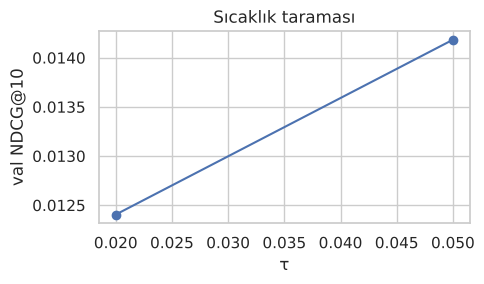

Seçilen ölçek: 20.0 (τ=0.050)


In [16]:
best_scale, temp_res = CFG["BI_SCALE"], {}
if CFG["TUNE_TEMPERATURE"]:
    sub = DS_TRAIN.shuffle(seed=CFG["SEED"]).select(range(max(8, int(len(DS_TRAIN) * CFG["TEMP_FRACTION"]))))
    ev = GradedIREvaluator(VAL_IDS, "val", QP, DP)
    for sc in CFG["TEMP_GRID"]:
        m, _ = train_bi_encoder(sc, sub, 1, os.path.join(CFG["OUT_DIR"], f"temp_{sc}"), log_name=f"τ={1/sc:.3f}")
        temp_res[sc] = ev(m)["val_graded_ndcg@10"]
        print(f"  ölçek={sc} (τ={1/sc:.3f}) -> val NDCG@10={temp_res[sc]:.4f}")
        del m; free_mem()
    best_scale = max(temp_res, key=temp_res.get)
    plt.figure(figsize=(5, 3)); plt.plot([1 / s for s in temp_res], list(temp_res.values()), "o-")
    plt.xlabel("τ"); plt.ylabel("val NDCG@10"); plt.title("Sıcaklık taraması"); plt.tight_layout()
    plt.savefig(os.path.join(CFG["FIG_DIR"], "temperature_sweep.png"), dpi=120); plt.show()
print("Seçilen ölçek:", best_scale, f"(τ={1 / best_scale:.3f})")

### 7.2 Tam eğitim (early stopping + en iyi checkpoint)
Her `EVALS_PER_EPOCH` aralığında: train loss, **val loss**, val NDCG@10 / MRR@10 / P@10 / R@10 / R@50 / Top-1 loglanır;
en iyi val NDCG@10 checkpoint'i yüklenir; `EARLY_STOP_PATIENCE` değerlendirme boyunca iyileşme yoksa durur.

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 7070.89it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Mnrl Loss,Val Graded Ndcg@10,Val Mrr@10,Val P@10,Val R@10,Val R@50,Val Top1
14,4.504252,No log,4.112870,0.007459,0.004545,0.004545,0.000858,0.019516,0.000000


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 814.27it/s]

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 3238.08it/s]

Bi-encoder: 15 sn


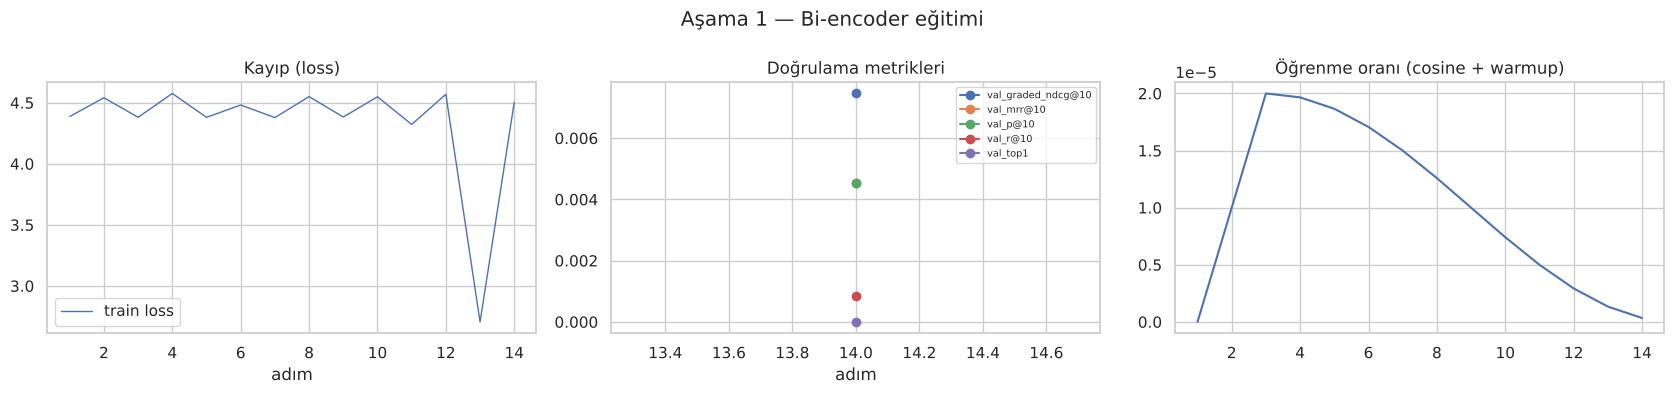

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 596.37it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   4%|▍         | 2/47 [00:00<00:02, 15.25it/s]

Batches:   9%|▊         | 4/47 [00:00<00:02, 16.17it/s]

...

Batches:  81%|████████  | 38/47 [00:02<00:00, 21.24it/s]

Batches:  87%|████████▋ | 41/47 [00:02<00:00, 21.09it/s]

Batches:  94%|█████████▎| 44/47 [00:02<00:00, 22.35it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 19.73it/s]

İnce ayarlı dense (tek başına): {'NDCG@10': 2.86, 'MRR@10': 6.12, 'P@10': 2.31, 'P@10_capped': 2.31, 'R@10': 0.29, 'R@50': 2.15, 'Top1': 0.0, 'Top1_exact(grade3)': 0.0}


In [17]:
bi_dir = os.path.join(CFG["OUT_DIR"], "bi_ckpt")
BI, bi_logs = train_bi_encoder(best_scale, DS_TRAIN, CFG["BI_EPOCHS"], bi_dir, cosent_ds=DS_COSENT, eval_ds=DS_VAL,
                               evaluator=GradedIREvaluator(VAL_IDS, "val", QP, DP), log_name="Bi-encoder")
bi_log_df = plot_logs(bi_logs, "Aşama 1 — Bi-encoder eğitimi", "stage1_training.png")
bi_log_df.to_csv(os.path.join(CFG["OUT_DIR"], "stage1_training_log.csv"), index=False)
BI.save(os.path.join(CFG["OUT_DIR"], "bi_encoder_best"))
E_jobs = encode(BI, job_texts(DP))
E_q = {"val": encode(BI, cv_texts(VAL_IDS, QP)), "test": encode(BI, cv_texts(TEST_IDS, QP))}
S_DENSE = {s: E_q[s] @ E_jobs.T for s in E_q}
print("İnce ayarlı dense (tek başına):", fmt(eval_scores(S_DENSE["test"], TEST_IDS, "Ours: Fine-tuned dense (tek)")))

## 8. Hibrit aday üretimi: Dense ⊕ BM25 → Reciprocal Rank Fusion (Cormack vd., 2009)
$\mathrm{RRF}(d) = \sum_{r\in\{\text{dense},\text{bm25}\}} \frac{1}{k + \mathrm{rank}_r(d)}$, $k=60$. Aşama 2'ye Top-50 aday gider;
**Recall@50** aday üretiminin tavanını gösterir.

In [18]:
def hybrid(Sd, Sb, cols=None):
    if cols is not None:
        Sd, Sb = Sd[:, cols], Sb[:, cols]
    dr, br = core.ranks_from_scores(Sd), core.ranks_from_scores(Sb)
    fused = core.rrf_scores([dr, br], k=CFG["RRF_K"])
    return fused, dr, br, core.ranks_from_scores(fused)

HYB = {s: hybrid(S_DENSE[s], S_BM25[s]) for s in ("val", "test")}
print("Aşama 1 (Ours) Hybrid RRF:", fmt(eval_scores(HYB["test"][0], TEST_IDS, "S1: Fine-tuned bi-encoder + BM25 (RRF)")))
for k in (10, 50, 100):
    print(f"  Recall@{k} (aday tavanı):", round(100 * RESULTS["S1: Fine-tuned bi-encoder + BM25 (RRF)"]["summary"][f"R@{k}"], 2))

Aşama 1 (Ours) Hybrid RRF: {'NDCG@10': 33.29, 'MRR@10': 53.52, 'P@10': 31.15, 'P@10_capped': 36.16, 'R@10': 16.95, 'R@50': 37.73, 'Top1': 34.62, 'Top1_exact(grade3)': 7.69}
  Recall@10 (aday tavanı): 16.95
  Recall@50 (aday tavanı): 37.73
  Recall@100 (aday tavanı): 48.72


## 9. Aşama 2a — Cross-encoder ince ayarı (bge-reranker-v2-m3, **LambdaLoss**)
Girdi: `[CLS] CV [SEP] İlan [SEP]` (tam çapraz dikkat). Liste-tabanlı **LambdaLoss** (NDCG-Loss2++; Wang vd., 2018)
kademeli etiketleri (0–3) doğrudan optimize eder. Eğitim listeleri, ince ayarlı Aşama-1'in train anchor'lar için
getirdiği Top-50 içinden **zor** adaylardan kurulur (yalnız WARM ilanlar).

CE eğitim listesi: 60 | ortalama liste uzunluğu: 6.0 | etiket dağılımı: Counter({2: 178, 0: 116, 1: 39, 3: 27})


Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 5378.83it/s]

Step,Training Loss,Validation Loss,Val Graded Ndcg@10,Val Mrr@10,Val P@10,Val Top1
15,0.612782,No log,0.210486,0.376263,0.136364,0.227273


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 488.33it/s]

Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 3325.14it/s]

Cross-encoder: 6 sn


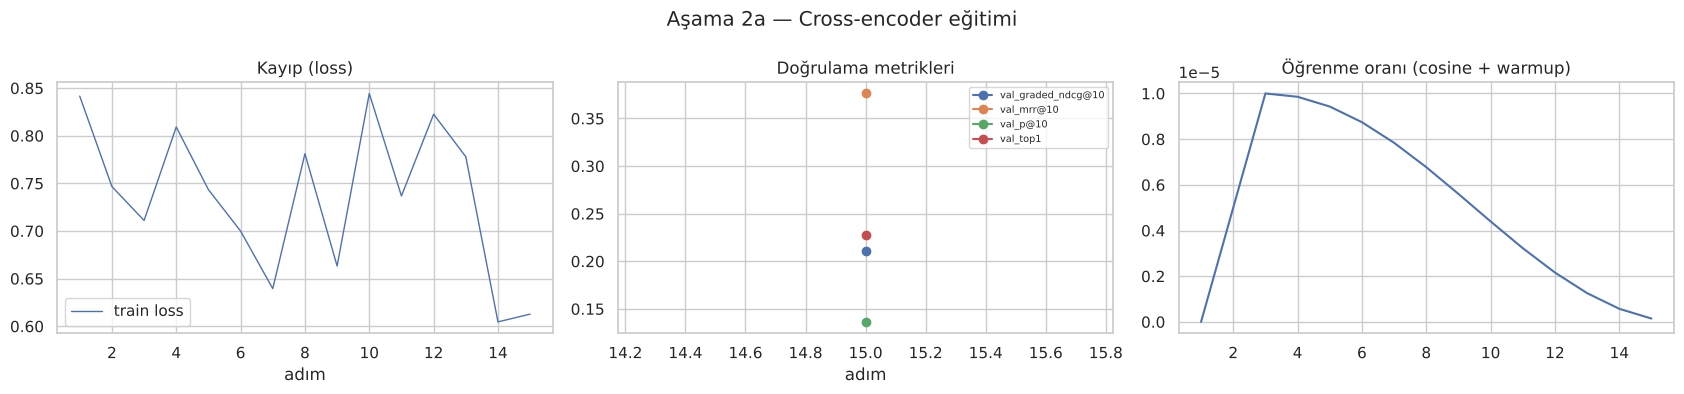

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 457.49it/s]

Hybrid + Cross-encoder: {'NDCG@10': 30.99, 'MRR@10': 48.97, 'P@10': 30.77, 'P@10_capped': 33.15, 'R@10': 12.77, 'R@50': 37.73, 'Top1': 30.77, 'Top1_exact(grade3)': 7.69}


In [19]:
def ce_pairs(qid, idxs):
    q = core.compact_cv_for_ce(CV.loc[int(qid), "cv_struct"])
    return [(q, core.compact_job_for_ce(jobs.job_struct.iloc[int(j)])) for j in idxs]

# train listeleri
tr_anchor = anchors if CFG["CE_TRAIN_QUERIES"] is None else anchors[: CFG["CE_TRAIN_QUERIES"]]
E_anc_ft = encode(BI, cv_texts(tr_anchor, QP))
fused_tr, *_ = hybrid(E_anc_ft @ E_jobs.T, bm25_matrix(tr_anchor))
fused_tr[:, COLD] = -np.inf
cand_tr = core.topk_indices(fused_tr, CFG["N_CANDIDATES"])
r_ = np.random.default_rng(CFG["SEED"])
Q, DOCS, LABELS = [], [], []
for i, a in enumerate(tr_anchor):
    cands = [int(j) for j in cand_tr[i]]
    pos = [j for j in cands if grade(a, j) >= 2][:4]
    if not pos:
        extra = [j for j, g in QRELS[a].items() if g >= 2 and WARM[j]]
        if not extra: continue
        pos = [int(r_.choice(extra))]
    neg = [j for j in cands if j not in pos][: CFG["CE_DOCS_PER_QUERY"] - len(pos)]
    docs = pos + neg
    docs = [docs[k] for k in r_.permutation(len(docs))]
    pairs = ce_pairs(a, docs)
    Q.append(pairs[0][0]); DOCS.append([p[1] for p in pairs]); LABELS.append([float(grade(a, j)) for j in docs])
DS_CE = Dataset.from_dict({"query": Q, "docs": DOCS, "labels": LABELS})
print("CE eğitim listesi:", len(DS_CE), "| ortalama liste uzunluğu:", np.mean([len(d) for d in DOCS]).round(1),
      "| etiket dağılımı:", Counter(int(x) for l in LABELS for x in l))

class GradedRerankEvaluator(SentenceEvaluator):
    # Val Top-50 hibrit adaylarını cross-encoder ile yeniden sıralayıp tam-havuz NDCG@10 hesaplar
    def __init__(self, qids, fused):
        super().__init__(); self.qids = list(qids); self.name = "val"
        f = fused.copy(); f[:, COLD] = -np.inf          # model seçimi yalnız WARM ilanlarla
        self.fused = f
        self.cand = core.topk_indices(f, CFG["N_CANDIDATES"])
        self.primary_metric = "graded_ndcg@10"; self.greater_is_better = True
    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        sc = ce_score_matrix(model, self.qids, self.cand)
        rl = {q: [j for j in lst if not COLD[j]] for q, lst in rerank_lists(self.qids, self.cand, sc, self.fused).items()}
        s = evaluate(rl, cols=WARM_COLS, store=False)
        m = self.prefix_name_to_metrics({"graded_ndcg@10": s["NDCG@10"], "mrr@10": s["MRR@10"], "p@10": s["P@10"],
                                          "top1": s["Top1"]}, self.name)
        self.store_metrics_in_model_card_data(model, m, epoch, steps)
        return m

@torch.no_grad()
def ce_score_matrix(model, qids, cand, bs=64):
    # Ham logit (Sigmoid yok), fp32/TF32, autocast yok -> çıkarımdaki SOTAMatcher ile birebir aynı fonksiyon
    pairs = [p for i, q in enumerate(qids) for p in ce_pairs(q, cand[i])]
    return core.ce_predict(model, pairs, batch_size=bs).reshape(len(qids), -1)

def rerank_lists(qids, cand, new_scores, base_scores, k=100):
    # aday listesi yeni skorla sıralanır; kalan sıralar Aşama-1 sırasıyla eklenir
    base_top = core.topk_indices(base_scores, min(k, base_scores.shape[1]))
    out = {}
    for i, q in enumerate(qids):
        head = [int(cand[i][o]) for o in np.argsort(-new_scores[i], kind="stable")]
        hs = set(head)
        out[int(q)] = (head + [int(j) for j in base_top[i] if j not in hs])[:k]
    return out

set_seed(CFG["SEED"])
CE = CrossEncoder(CFG["CROSS_ENCODER_BASE"], num_labels=1, max_length=CFG["CE_MAX_LEN"], device=DEVICE)
if CFG["GRAD_CKPT"]:
    enable_grad_ckpt(CE)
ce_logs = LogCollector()
ce_args = CrossEncoderTrainingArguments(
    output_dir=os.path.join(CFG["OUT_DIR"], "ce_ckpt"), num_train_epochs=CFG["CE_EPOCHS"],
    per_device_train_batch_size=CFG["CE_BATCH"], learning_rate=CFG["CE_LR"], warmup_steps=0.1, lr_scheduler_type="cosine",
    weight_decay=0.01, optim="adamw_torch_fused" if DEVICE == "cuda" else "adamw_torch", bf16=BF16, fp16=FP16,
    tf32=True if TF32 else None, eval_strategy="steps",
    eval_steps=max(1, len(DS_CE) // CFG["CE_BATCH"] // CFG["EVALS_PER_EPOCH"]),
    save_strategy="steps", save_steps=max(1, len(DS_CE) // CFG["CE_BATCH"] // CFG["EVALS_PER_EPOCH"]),
    save_total_limit=2, save_only_model=True, load_best_model_at_end=True, metric_for_best_model="eval_val_graded_ndcg@10",
    greater_is_better=True, logging_steps=10 if not DRY_RUN else 1, report_to="none", seed=CFG["SEED"])
ce_trainer = CrossEncoderTrainer(model=CE, args=ce_args, train_dataset=DS_CE,
                                 loss=LambdaLoss(CE, mini_batch_size=CFG["CE_MINI_BATCH"]),
                                 evaluator=GradedRerankEvaluator(VAL_IDS, HYB["val"][0]),
                                 callbacks=[ce_logs, EarlyStoppingCallback(early_stopping_patience=CFG["EARLY_STOP_PATIENCE"])])
t0 = time.time(); ce_trainer.train(); drop_amp_wrapper(CE); print(f"Cross-encoder: {time.time() - t0:.0f} sn")
shutil.rmtree(os.path.join(CFG["OUT_DIR"], "ce_ckpt"), ignore_errors=True)
ce_log_df = plot_logs(ce_logs.rows, "Aşama 2a — Cross-encoder eğitimi", "stage2a_training.png")
ce_log_df.to_csv(os.path.join(CFG["OUT_DIR"], "stage2a_training_log.csv"), index=False)
CE.save(os.path.join(CFG["OUT_DIR"], "cross_encoder_best"))

CAND = {s: core.topk_indices(HYB[s][0], CFG["N_CANDIDATES"]) for s in ("val", "test")}
CE_S = {s: ce_score_matrix(CE, VAL_IDS if s == "val" else TEST_IDS, CAND[s]) for s in ("val", "test")}
print("Hybrid + Cross-encoder:", fmt(evaluate(rerank_lists(TEST_IDS, CAND["test"], CE_S["test"], HYB["test"][0]),
                                             "Ours: Hybrid + Cross-encoder")))

## 10. Aşama 2b — LambdaMART (LightGBM `lambdarank`) — elle çarpan yerine öğrenilen sıralama
Özellik vektörü (her (CV, aday ilan) çifti için):
dense kosinüs/sıra/z-skor, BM25 skor/sıra, RRF skor/sıra, cross-encoder logit/sıra/z-skor, **tahmini** sektör olasılığı
$P_{cv}(\text{sektör}=\text{ilanın sektörü})$, **tahmini** yaka olasılıkları ve uyumu, kıdem (metinden) – ilan seviyesi farkı,
lokasyon/remote uyumu, beceri kesişimi (overlap/Jaccard), unvan karakter-n-gram benzerliği …

* Sektör/yaka sınıflandırıcıları **yalnızca train CV'leriyle** eğitilir; val/test için tahminler örneklem-dışıdır.
* LambdaMART **val sorgularında** eğitilir (yığınlama / stacking: Aşama-1/2a modelleri bu sorgularla hiç **eğitilmedi**;
  val yalnızca τ seçimi ve erken durdurma için kullanıldı — bu, val özniteliklerini test'e göre en fazla hafifçe iyimser
  yapar, test performansını şişirmez). **Cold** ilanlar LTR eğitiminden de çıkarılır; Optuna + GroupKFold (sorgu bazlı,
  erken durdurma için ayrı iç bölme) ile hiperparametre seçilir.

In [20]:
tr_cv = cvs[cvs.cv_id.isin(S["train"]) & ((cvs.source == "real") | CFG["USE_SYNTHETIC"])]
ATTR = core.AttributeModels().fit(tr_cv.cv_struct.tolist(), tr_cv.gold_industry.tolist(), tr_cv.headline.tolist(),
                                  (tr_cv.gold_collar == "BLUE").astype(int).tolist())
TSIM = core.TitleSimilarity().fit(list(jobs.title) + tr_cv.headline.tolist())
JT = core.JobTable.build(jobs, ATTR, TSIM)
# Sınıflandırıcı kalitesi (val, örneklem-dışı) — mükemmel DEĞİL: altın etiketin vekili olmadığını gösterir
va = cvs.set_index("cv_id").loc[VAL_IDS]
ind_acc = np.mean(np.array(core.INDUSTRIES)[ATTR.industry_proba(va.cv_struct.tolist()).argmax(1)] == va.gold_industry.to_numpy(dtype=object))
col_acc = np.mean((ATTR.blue_proba(va.headline.tolist()) > 0.5) == (va.gold_collar.to_numpy(dtype=object) == "BLUE"))
print(f"Val sektör sınıflandırıcı doğruluğu: %{100*ind_acc:.1f} | yaka: %{100*col_acc:.1f}")

def ltr_frame(qids, Sd, Sb, hyb, cand, ce_s):
    fused, dr, br, rr = hyb
    parts = []
    for i, q in enumerate(qids):
        r = CV.loc[int(q)]
        qm = core.QueryMeta.from_text(r.headline, r.cv_text, ATTR, r.cv_struct)
        c = cand[i]
        f = core.build_pair_features(qm, c, JT, TSIM, Sd[i, c], Sb[i, c], fused[i, c], dr[i, c], br[i, c], rr[i, c], ce_s[i])
        core.assert_no_gold_columns(f, "ltr")
        f.insert(0, "job_idx", c); f.insert(0, "qid", int(q))
        f["grade"] = [grade(q, j) for j in c]
        parts.append(f)
    return pd.concat(parts, ignore_index=True)

LTR = {s: ltr_frame(VAL_IDS if s == "val" else TEST_IDS, S_DENSE[s], S_BM25[s], HYB[s], CAND[s], CE_S[s]) for s in ("val", "test")}
FEATS = core.FEATURE_COLUMNS
print("LTR çerçeveleri:", {s: LTR[s].shape for s in LTR}, "| özellik sayısı:", len(FEATS))
LTR["val"].head()

Val sektör sınıflandırıcı doğruluğu: %66.7 | yaka: %87.5


LTR çerçeveleri: {'val': (1200, 38), 'test': (1350, 38)} | özellik sayısı: 35


,qid,job_idx,dense_cos,dense_rank_log,dense_z,dense_gap_top,bm25,bm25_rank_log,bm25_z,rrf,...,job_hybrid,loc_ok,skill_overlap,skill_jaccard,title_sim,title_tok_overlap,job_desc_len_log,cv_years_exp,cv_years_missing,grade
0,10306,2624,1.000000,3.433987,0.491595,0.000000,57.680862,3.555348,0.201240,0.021749,...,1.0,0.0,0.0,0.000000,0.177675,0.111111,6.981935,11.0,0.0,0
1,10306,2530,0.999992,4.605170,0.452327,-0.000008,106.538467,1.791759,1.442452,0.021674,...,1.0,0.0,0.2,0.029703,0.009468,0.000000,7.038784,11.0,0.0,0
2,10306,2665,0.999992,4.997212,0.450828,-0.000008,102.701653,1.945910,1.344979,0.019982,...,1.0,0.0,0.0,0.000000,0.668007,0.375000,6.909753,11.0,0.0,2
3,10306,1478,1.000000,1.945910,0.491595,0.000000,32.923016,5.575949,-0.427725,0.018247,...,1.0,0.0,0.0,0.000000,0.000000,0.000000,6.933423,11.0,0.0,0
4,10306,2658,0.999992,4.990433,0.450828,-0.000008,67.603386,2.944439,0.453319,0.017675,...,1.0,0.0,0.0,0.000000,0.612691,0.250000,6.963190,11.0,0.0,0


En iyi CV NDCG@10 (val, GroupKFold; erken durdurma ayrı iç bölmede): 0.4646 | parametreler: {'learning_rate': 0.13394334706750485, 'num_leaves': 41, 'min_child_samples': 72, 'colsample_bytree': 0.5102922471479012, 'subsample': 0.9849549260809971, 'reg_alpha': 0.31044435499483225, 'reg_lambda': 8.148018307012941e-07} | ağaç: 14
Aşama 2 (Ours, tam boru hattı): {'NDCG@10': 58.17, 'MRR@10': 75.51, 'P@10': 50.38, 'P@10_capped': 56.65, 'R@10': 25.05, 'R@50': 37.73, 'Top1': 65.38, 'Top1_exact(grade3)': 11.54}


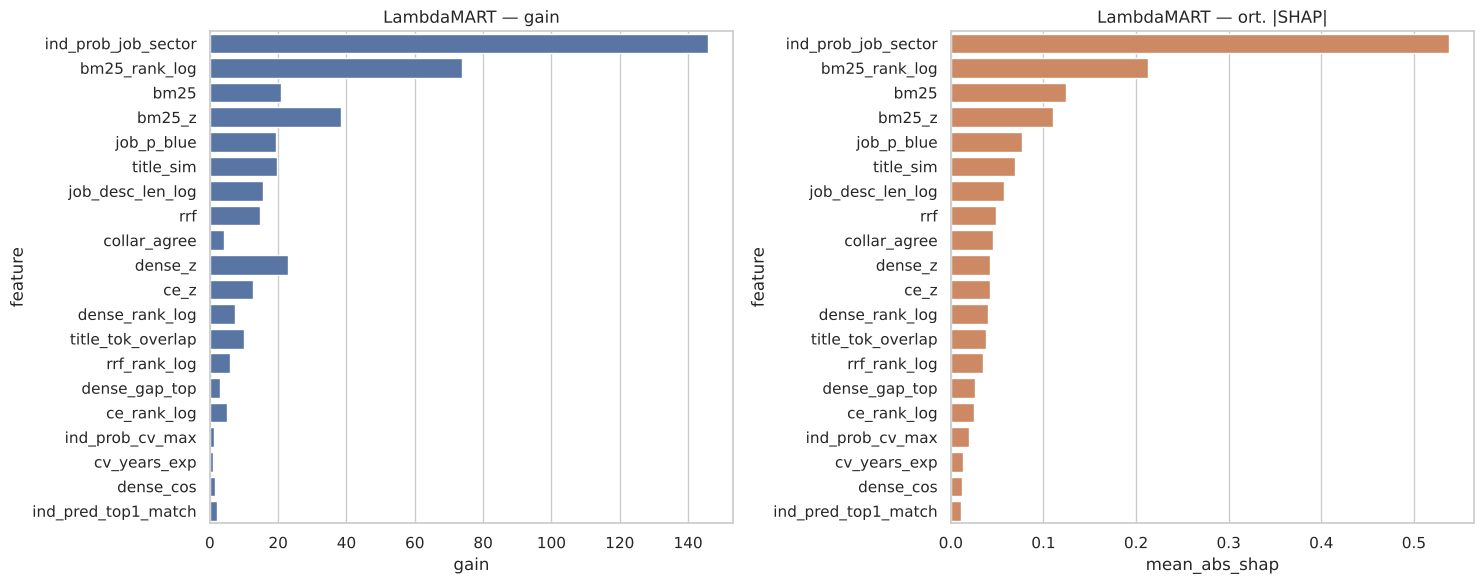

In [21]:
from sklearn.model_selection import GroupKFold

ltr_tr = LTR["val"][~COLD[LTR["val"].job_idx.to_numpy()]].reset_index(drop=True)   # cold ilanlar LTR eğitimine girmez
def groups_of(df):
    return df.groupby("qid", sort=False).size().to_numpy()

def ltr_rank_eval(model, df, base_hyb_scores, qids):
    df = df.copy(); df["s"] = model.predict(df[FEATS].to_numpy(np.float32))
    ranked = {}
    for q, g in df.groupby("qid", sort=False):
        ranked[int(q)] = g.sort_values("s", ascending=False).job_idx.astype(int).tolist()
    return evaluate(ranked, cols=WARM_COLS, store=False)["NDCG@10"]   # cold ilan dereceleri seçim sinyaline karışmaz

def objective(trial):
    params = dict(
        objective="lambdarank", metric="ndcg", eval_at=[10], n_estimators=CFG["LTR_MAX_ROUNDS"],
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 7, 63),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 100),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        random_state=CFG["SEED"], verbose=-1)
    scores, iters = [], []
    r_ = np.random.default_rng(CFG["SEED"] + trial.number)
    for tr_i, va_i in GroupKFold(n_splits=CFG["LTR_FOLDS"]).split(ltr_tr, groups=ltr_tr.qid):
        a_all, b = ltr_tr.iloc[tr_i], ltr_tr.iloc[va_i].sort_values("qid", kind="stable")
        # erken durdurma için eğitim katmanının İÇİNDEN ayrı sorgular; dış katman (b) yalnız puanlamada kullanılır
        qa = a_all.qid.unique()
        es_q = set(r_.choice(qa, size=max(2, int(0.15 * len(qa))), replace=False).tolist())
        a = a_all[~a_all.qid.isin(es_q)].sort_values("qid", kind="stable")
        es = a_all[a_all.qid.isin(es_q)].sort_values("qid", kind="stable")
        m = lgb.LGBMRanker(**params)
        m.fit(a[FEATS], a.grade, group=groups_of(a), eval_set=[(es[FEATS], es.grade)], eval_group=[groups_of(es)],
              callbacks=[lgb.early_stopping(100 if not DRY_RUN else 10, verbose=False)])
        iters.append(m.best_iteration_ or CFG["LTR_MAX_ROUNDS"])
        scores.append(ltr_rank_eval(m, b, None, b.qid.unique()))
    trial.set_user_attr("n_estimators", int(np.mean(iters)))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=CFG["SEED"]))
study.optimize(objective, n_trials=CFG["LTR_TRIALS"], show_progress_bar=not DRY_RUN)
LTR_BEST = dict(study.best_params); n_est = study.best_trial.user_attrs["n_estimators"]
print(f"En iyi CV NDCG@10 (val, GroupKFold; erken durdurma ayrı iç bölmede): {study.best_value:.4f} | "
      f"parametreler: {LTR_BEST} | ağaç: {n_est}")
ltr_tr = ltr_tr.sort_values("qid", kind="stable")
RANKER = lgb.LGBMRanker(objective="lambdarank", metric="ndcg", eval_at=[10], n_estimators=max(10, n_est), subsample_freq=1,
                        random_state=CFG["SEED"], verbose=-1, **LTR_BEST)
RANKER.fit(ltr_tr[FEATS], ltr_tr.grade, group=groups_of(ltr_tr))

def ltr_scores(df):
    return RANKER.predict(df[FEATS].to_numpy(np.float32)).reshape(-1, CFG["N_CANDIDATES"])

LTR_S = {"test": ltr_scores(LTR["test"])}
FULL_RANKED = rerank_lists(TEST_IDS, CAND["test"], LTR_S["test"], HYB["test"][0])
print("Aşama 2 (Ours, tam boru hattı):", fmt(evaluate(FULL_RANKED, "S2: Hybrid + Cross-encoder + LambdaMART")))

# Önem: gain + SHAP (pred_contrib) ortalama |katkı|
imp = pd.DataFrame({"feature": FEATS, "gain": RANKER.booster_.feature_importance("gain")})
contrib = RANKER.booster_.predict(LTR["test"][FEATS].to_numpy(np.float32), pred_contrib=True)[:, :-1]
imp["mean_abs_shap"] = np.abs(contrib).mean(0)
imp = imp.sort_values("mean_abs_shap", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=imp.head(20), y="feature", x="gain", ax=ax[0], color="#4C72B0"); ax[0].set_title("LambdaMART — gain")
sns.barplot(data=imp.head(20), y="feature", x="mean_abs_shap", ax=ax[1], color="#DD8452"); ax[1].set_title("LambdaMART — ort. |SHAP|")
fig.tight_layout(); fig.savefig(os.path.join(CFG["FIG_DIR"], "ltr_importance.png"), dpi=120); plt.show()

## 11. Ablation çalışması — aynı sızıntısız test kümesinde 5 sistem
Tüm satırlar **aynı** test sorguları, **aynı** 3.000 ilanlık havuz ve **aynı** kademeli qrels ile ölçülür.
Parantez içi: NDCG@10 için %95 bootstrap güven aralığı. `p` = bir önceki satıra göre iki yönlü Fisher randomizasyon testi.
İkinci tablo her bileşenin (ince ayar, BM25 füzyonu, cross-encoder, LambdaMART) katkısını ayrı ayrı test eder.

,NDCG@10,MRR@10,P@10,P@10_capped,R@10,R@50,Top1,Top1_exact(grade3),NDCG@10 %95 GA,sorgu,p (önceki satıra göre)
Sistem,,,,,,,,,,,
B1: BM25,57.30,84.94,51.15,58.44,26.32,45.72,76.92,11.54,"[48.7, 66.0]",26,NaN
B2: Zero-shot e5-small,3.04,6.16,2.69,2.69,0.25,2.16,0.00,0.00,"[1.6, 4.7]",26,0.000500
B3: Eski (e5-small + CosineSimLoss),1.81,1.36,1.15,1.15,0.07,1.51,0.00,0.00,"[0.7, 3.3]",26,0.147426
S1: Fine-tuned bi-encoder + BM25 (RRF),33.29,53.52,31.15,36.16,16.95,37.73,34.62,7.69,"[26.3, 40.8]",26,0.000500
S2: Hybrid + Cross-encoder + LambdaMART,58.17,75.51,50.38,56.65,25.05,37.73,65.38,11.54,"[48.3, 68.4]",26,0.000500
Ref: Zero-shot base bi-encoder,3.04,6.16,2.69,2.69,0.25,2.16,0.00,0.00,"[1.6, 4.7]",26,NaN
Ours: Fine-tuned dense (tek),2.86,6.12,2.31,2.31,0.29,2.15,0.00,0.00,"[1.6, 4.3]",26,NaN
Ours: Hybrid + Cross-encoder,30.99,48.97,30.77,33.15,12.77,37.73,30.77,7.69,"[23.4, 39.3]",26,NaN


,sorgu,ΔNDCG@10 (puan),p (NDCG@10),ΔTop1 (puan),p (Top1)
Karşılaştırma,,,,,
İnce ayar (dense: fine-tuned vs zero-shot base),26,-0.18,0.688156,0.00,1.000000
BM25 füzyonu (S1 vs fine-tuned dense),26,30.43,0.000500,34.62,0.004498
Cross-encoder (Hybrid+CE vs S1),26,-2.30,0.299850,-3.85,1.000000
LambdaMART (S2 vs Hybrid+CE),26,27.19,0.000500,34.62,0.012994
Toplam (S2 vs B1 BM25),26,0.87,0.783108,-11.54,0.500250
Toplam (S2 vs B3 eski sistem),26,56.36,0.000500,65.38,0.000500


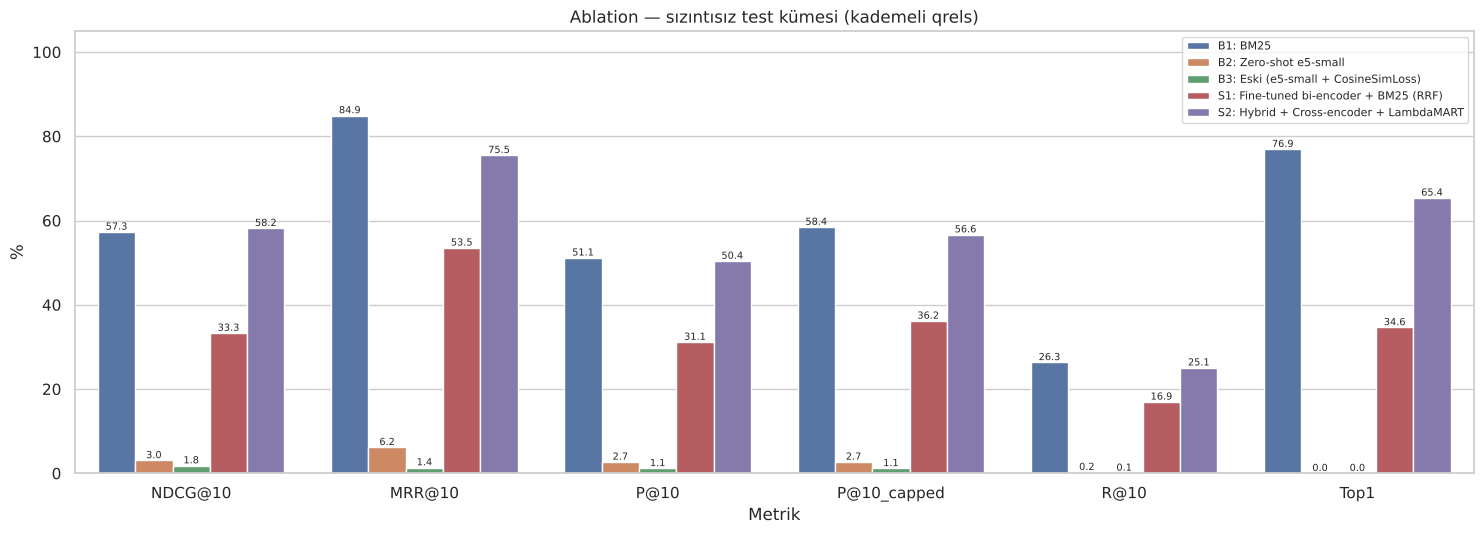


Hedef karşılaştırması (tam boru hattı):
  Top1        :  65.38  hedef > 88.0  ->  karşılanmadı
  NDCG@10     :  58.17  hedef > 92.0  ->  karşılanmadı
  P@10        :  50.38  hedef > 85.0  ->  karşılanmadı
  P@10_capped :  56.65  hedef > 85.0  ->  karşılanmadı


In [22]:
MAIN = ["B1: BM25", "B2: Zero-shot e5-small", "B3: Eski (e5-small + CosineSimLoss)",
        "S1: Fine-tuned bi-encoder + BM25 (RRF)", "S2: Hybrid + Cross-encoder + LambdaMART"]
EXTRA = ["Ref: Zero-shot base bi-encoder", "Ours: Fine-tuned dense (tek)", "Ours: Hybrid + Cross-encoder"]
def per_q(name):
    return RESULTS[name]["per_query"].set_index("qid")
rows = []
for i, n in enumerate(MAIN + EXTRA):
    s = RESULTS[n]["summary"]; pq = per_q(n)
    lo, hi = core.bootstrap_ci(pq["NDCG@10"].to_numpy(), seed=CFG["SEED"])
    row = {"Sistem": n, **fmt(s), "NDCG@10 %95 GA": f"[{100*lo:.1f}, {100*hi:.1f}]", "sorgu": s["n_queries"]}
    if 0 < i < len(MAIN):
        prev = per_q(MAIN[i - 1]); common = pq.index.intersection(prev.index)
        row["p (önceki satıra göre)"] = core.paired_randomization_test(pq.loc[common, "NDCG@10"], prev.loc[common, "NDCG@10"],
                                                                        n_perm=2000 if DRY_RUN else 10000, seed=CFG["SEED"])
    rows.append(row)
ABL = pd.DataFrame(rows).set_index("Sistem")
ABL.to_csv(os.path.join(CFG["OUT_DIR"], "ablation_test.csv"))
display(ABL)

# Bileşen katkıları: her bileşen eklendiğinde NDCG@10 / Top-1 farkı ve iki yönlü eşleştirilmiş randomizasyon p-değeri
PAIRS = {
    "İnce ayar (dense: fine-tuned vs zero-shot base)": ("Ours: Fine-tuned dense (tek)", "Ref: Zero-shot base bi-encoder"),
    "BM25 füzyonu (S1 vs fine-tuned dense)": (MAIN[3], "Ours: Fine-tuned dense (tek)"),
    "Cross-encoder (Hybrid+CE vs S1)": ("Ours: Hybrid + Cross-encoder", MAIN[3]),
    "LambdaMART (S2 vs Hybrid+CE)": (MAIN[4], "Ours: Hybrid + Cross-encoder"),
    "Toplam (S2 vs B1 BM25)": (MAIN[4], MAIN[0]),
    "Toplam (S2 vs B3 eski sistem)": (MAIN[4], MAIN[2]),
}
prow = []
for lab, (a_n, b_n) in PAIRS.items():
    pa, pb = per_q(a_n), per_q(b_n); cm = pa.index.intersection(pb.index)
    rec = {"Karşılaştırma": lab, "sorgu": len(cm)}
    for met in ("NDCG@10", "Top1"):
        rec[f"Δ{met} (puan)"] = round(100 * float((pa.loc[cm, met] - pb.loc[cm, met]).mean()), 2)
        rec[f"p ({met})"] = core.paired_randomization_test(pa.loc[cm, met], pb.loc[cm, met],
                                                          n_perm=2000 if DRY_RUN else 10000, seed=CFG["SEED"])
    prow.append(rec)
COMP = pd.DataFrame(prow).set_index("Karşılaştırma")
COMP.to_csv(os.path.join(CFG["OUT_DIR"], "ablation_component_tests.csv"))
display(COMP)

m = ["NDCG@10", "MRR@10", "P@10", "P@10_capped", "R@10", "Top1"]
plot_df = ABL.loc[MAIN, m].reset_index().melt(id_vars="Sistem", var_name="Metrik", value_name="%")
plt.figure(figsize=(15, 5.5))
ax = sns.barplot(data=plot_df, x="Metrik", y="%", hue="Sistem")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=7)
plt.title("Ablation — sızıntısız test kümesi (kademeli qrels)"); plt.ylim(0, 105); plt.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(os.path.join(CFG["FIG_DIR"], "ablation.png"), dpi=130); plt.show()

TARGETS = {"Top1": 88.0, "NDCG@10": 92.0, "P@10": 85.0, "P@10_capped": 85.0}
full = ABL.loc[MAIN[-1]]
print("\nHedef karşılaştırması (tam boru hattı):")
for k, v in TARGETS.items():
    print(f"  {k:12s}: {full[k]:6.2f}  hedef > {v}  ->  {'KARŞILANDI' if full[k] > v else 'karşılanmadı'}")

### 11.1 Sektör bazında sonuçlar ve soğuk-başlangıç (eğitimde hiç görülmemiş ilanlar)

In [23]:
pq = per_q(MAIN[-1]).join(CV[["gold_industry"]], how="left")
sec = pq.groupby("gold_industry").agg(n=("NDCG@10", "size"), NDCG10=("NDCG@10", "mean"), P10=("P@10", "mean"), Top1=("Top1", "mean"))
sec[["NDCG10", "P10", "Top1"]] *= 100
display(sec.sort_values("NDCG10").round(1))

# Soğuk-başlangıç: korpus yalnızca COLD ilanlar; tüm boru hattı bu alt-korpusta yeniden çalıştırılır
cold_cols = np.where(COLD)[0]
def full_pipeline_on(cols, qids, Sd, Sb):
    # Sıra/RRF öznitelikleri eğitimdeki gibi TÜM korpus üzerinden hesaplanır (dağılım kayması olmasın);
    # yalnızca aday kümesi alt-korpusla (cols) sınırlanır.
    fused, dr, br, rr = hybrid(Sd, Sb)
    mask = np.full(fused.shape[1], -np.inf); mask[cols] = 0.0
    K = min(CFG["N_CANDIDATES"], len(cols))
    cg = core.topk_indices(fused + mask[None, :], K)
    ce_s = ce_score_matrix(CE, qids, cg)
    parts = []
    for i, q in enumerate(qids):
        r = CV.loc[int(q)]; qm = core.QueryMeta.from_text(r.headline, r.cv_text, ATTR, r.cv_struct)
        c = cg[i]
        f = core.build_pair_features(qm, c, JT, TSIM, Sd[i, c], Sb[i, c], fused[i, c], dr[i, c], br[i, c], rr[i, c], ce_s[i])
        core.assert_no_gold_columns(f, "cold-start")
        parts.append(f)
    sc = RANKER.predict(pd.concat(parts)[FEATS].to_numpy(np.float32)).reshape(len(qids), K)
    out = {}
    for i, q in enumerate(qids):
        out[int(q)] = [int(cg[i][o]) for o in np.argsort(-sc[i], kind="stable")]
    return out, fused

cold_rows = {}
cold_rows["B1: BM25"] = evaluate(ranked_lists(S_BM25["test"][:, cold_cols], TEST_IDS, cols=cold_cols), cols=cold_cols, store=False)
cold_rows["B3: Eski"] = evaluate(ranked_lists(S_LEGACY[:, cold_cols], TEST_IDS, cols=cold_cols), cols=cold_cols, store=False)
cold_rows["Ours: dense"] = evaluate(ranked_lists(S_DENSE["test"][:, cold_cols], TEST_IDS, cols=cold_cols), cols=cold_cols, store=False)
fr, _ = full_pipeline_on(cold_cols, TEST_IDS, S_DENSE["test"], S_BM25["test"])
cold_rows["Ours: tam boru hattı"] = evaluate(fr, cols=cold_cols, store=False)
COLD_TBL = pd.DataFrame({k: fmt(v) | {"sorgu": v["n_queries"]} for k, v in cold_rows.items()}).T
print(f"Soğuk-başlangıç alt korpusu: {len(cold_cols)} ilan (hiçbir eğitim sinyalinde kullanılmadı)")
display(COLD_TBL)
COLD_TBL.to_csv(os.path.join(CFG["OUT_DIR"], "cold_start_test.csv"))

,n,NDCG10,P10,Top1
gold_industry,,,,
APPAREL_TEXTILE,1,11.1,10.0,0.0
FINANCE_ACCOUNTING,1,18.5,20.0,0.0
SUPPLY_CHAIN_LOGISTICS,2,35.3,25.0,50.0
AVIATION,1,49.9,20.0,100.0
MARKETING_MEDIA,1,51.7,50.0,0.0
LOGISTICS_DRIVER,1,52.5,20.0,100.0
IT_SOFTWARE,6,53.6,68.3,66.7
INDUSTRIAL_MANUFACTURING,4,55.3,45.0,50.0
CONSTRUCTION,2,59.6,30.0,50.0


Soğuk-başlangıç alt korpusu: 301 ilan (hiçbir eğitim sinyalinde kullanılmadı)


,NDCG@10,MRR@10,P@10,P@10_capped,R@10,R@50,Top1,Top1_exact(grade3),sorgu
B1: BM25,44.53,60.20,22.38,55.76,50.57,79.43,42.86,4.76,21.0
B3: Eski,4.43,2.00,2.86,3.98,3.23,14.72,0.00,0.00,21.0
Ours: dense,7.68,10.05,4.29,7.03,5.78,28.47,4.76,0.00,21.0
Ours: tam boru hattı,56.69,71.59,26.19,60.05,53.45,74.58,61.90,4.76,21.0


## 12. Hata analizi ve uç-durum (edge-case) kanıtları
Vitrin adayları (Baklava ustası, uçuş dispeçeri, Java geliştiricisi, Java stajyeri) **test** kümesine sabitlenmiştir;
hiçbir model bunları eğitimde görmedi. Eski yaklaşım (Baseline 3) ile tam boru hattımızın Top-10 listeleri ve
**tuzak ilanların** (leksikal / alt-kelime benzeri ama alakasız) sıraları yan yana gösterilir.

In [24]:
def rank_of(ranked_list, j):
    try: return ranked_list.index(int(j)) + 1
    except ValueError: return ">100"

B3_RANKED = ranked_lists(S_LEGACY, TEST_IDS)
pos_of = {q: i for i, q in enumerate(TEST_IDS)}
TS_CV = TSIM.transform([CV.loc[q, "headline"] for q in SHOWCASE])
for si, q in enumerate(SHOWCASE):
    r = CV.loc[q]
    print("=" * 110); print(f"ADAY {q}: {r.headline}  | (altın) {r.gold_specialty} / ISCO {r.gold_isco4} / kıdem {r.gold_seniority}")
    tbl = []
    for k in range(10):
        jb, jo = B3_RANKED[q][k], FULL_RANKED[q][k]
        tbl.append({"#": k + 1, "Eski (B3) ilan": jobs.title.iloc[jb][:45], "B3 grade": grade(q, jb),
                    "Bizim ilan": jobs.title.iloc[jo][:45], "Bizim grade": grade(q, jo)})
    t = pd.DataFrame(tbl).set_index("#")
    display(t)
    # Tuzaklar: unvanı en çok benzeyen ama grade 0 olan ilanlar (alt-kelime / sözcük tuzağı)
    sims = np.asarray((JT.title_mat @ TS_CV[si].T).todense()).ravel()
    traps = [j for j in np.argsort(-sims) if grade(q, j) == 0][:5]
    trap_tbl = pd.DataFrame([{"Tuzak ilan": jobs.title.iloc[j], "sektör": jobs.industry.iloc[j], "unvan benzerliği": round(float(sims[j]), 2),
                              "Eski (B3) sıra": rank_of(B3_RANKED[q], j), "Bizim sıra": rank_of(FULL_RANKED[q], j)} for j in traps])
    display(trap_tbl)
    print(f"Eski Top-10 ortalama grade: {t['B3 grade'].mean():.2f} | Bizim Top-10 ortalama grade: {t['Bizim grade'].mean():.2f}")

ADAY 20951: Gaziantep Baklava & Yufka Ustası  | (altın) Baklava Ustası / ISCO 7512 / kıdem 3


,Eski (B3) ilan,B3 grade,Bizim ilan,Bizim grade
#,,,,
1,Yangın Güvenliği ve Acil Durum Müdahale Uzman,0,Gaziantep Usulü Baklava Ustası,2
2,Backend Geliştirici (Go & gRPC),0,Taş Fırın ve Ekmek Pişirme Ustası,2
3,Python Developer (Finansal Veri & Algoritmik,0,Geleneksel Şerbetli Tatlı Ustası,2
4,Node.js Backend Developer (NestJS & PostgreSQ,0,Taş Fırın Pide ve Lahmacun Ustası,2
5,Barista ve Kahve Servis Elemanı,1,Kol Böreği ve Boşnak Böreği Ustası,2
6,Hasta ve Yaşlı Bakıcısı (Caregiver),0,Taş Fırın Pide ve Lahmacun Ustası,2
7,Un ve Yem Değirmeni Operatörü,1,Taş Fırın Simit Ustası,2
8,Kıdemli Analitik Transfer ve Ar-Ge Koordinatö,0,Pide ve Lahmacun Ustası,2
9,Frontend Developer (React Native & React Web),0,Unlu Mamuller ve Fırın Ustası (Baker),2


,Tuzak ilan,sektör,unvan benzerliği,Eski (B3) sıra,Bizim sıra
0,Gemi Montaj Ustası,MARITIME,0.14,>100,>100
1,Zemin Şap Ustası,CONSTRUCTION,0.14,>100,>100
2,Kalıp ve Demir Ustası,CONSTRUCTION,0.13,>100,>100
3,Kaba ve İnce Sıva Ustası,CONSTRUCTION,0.13,>100,>100
4,Isı ve Ses Yalıtım Ustası,CONSTRUCTION,0.13,>100,>100


Eski Top-10 ortalama grade: 0.20 | Bizim Top-10 ortalama grade: 1.80
ADAY 10587: Flight Operations Dispatcher  | (altın) Uçuş Harekat Uzmanı (Dispeçer) / ISCO 4323 / kıdem 1


,Eski (B3) ilan,B3 grade,Bizim ilan,Bizim grade
#,,,,
1,Mekatronik ve Otomasyon Sistemleri Mühendisi,0,Uçuş Harekat Uzmanı (Flight Dispatcher),2
2,Çevresel Etki Değerlendirme (ÇED) Uzmanı,0,Uçuş Harekat Uzmanı (Flight Dispatcher),3
3,Kazan ve Basınçlı Kap Tasarım Mühendisi (ASME,0,Kabin Memuru / Flight Attendant,0
4,Finansal Teknoloji (FinTech) Ürün Yöneticisi,0,Master Mariner (Ocean-Going Ship Captain),0
5,Ses Mühendisi ve Mastering Uzmanı,0,Airport Operations Control (OCC) Manager,1
6,Demiryolu Sinyalizasyon ve Emniyet Mühendisi,0,Uçuş Operasyon ve Performans Mühendisi,1
7,Derin Öğrenme Donanım Mimarı (NPU/TPU),0,Uçuş Simülatörü ve Pilot Tip Eğitimi Öğretmen,1
8,Uluslararası Kaynak Mühendisi (IWE),0,Bank Branch Operations Officer,0
9,Yüksek Gerilim Tesisleri Mühendisi,0,Uçuş Emniyet ve Emniyet Yönetim Sistemleri (S,1


...

,Tuzak ilan,sektör,unvan benzerliği,Eski (B3) sıra,Bizim sıra
0,İş Geliştirme Uzmanı,SALES,0.26,>100,>100
1,Teknik Tekstil ve Koruyucu Kumaş Geliştirici,APPAREL_TEXTILE,0.22,>100,>100
2,E-Öğrenme ve İnteraktif İçerik Geliştirici,EDUCATION,0.21,>100,>100
3,Süreç Geliştirme Mühendisi,INDUSTRIAL_MANUFACTURING,0.20,>100,>100
4,Bayi Geliştirme Yöneticisi,SALES,0.20,>100,>100


Eski Top-10 ortalama grade: 0.20 | Bizim Top-10 ortalama grade: 1.80
ADAY 21029: Java ve Spring Boot Yazılım Stajyeri  | (altın) Backend Yazılım Geliştirici / ISCO 2512 / kıdem 0


,Eski (B3) ilan,B3 grade,Bizim ilan,Bizim grade
#,,,,
1,"Plastik, Rekonstrüktif ve Estetik Cerrahi Uzm",0,Java Yazılım Stajyeri (Spring Boot & Cloud -,3
2,Havacılık Sonlu Elemanlar ve Yorulma Analizi,0,Java Spring Boot Geliştirici,2
3,İthalat Operasyon Uzmanı,0,Junior Java Geliştirici (Mikroservis & Docker,3
4,Gümrük ve Dış Ticaret Mevzuat Uzmanı,0,Junior Fullstack Geliştirici (Java Spring & R,2
5,Radyofarmasi ve Nükleer Tıp Eczacısı,0,Junior Java Geliştirici (Spring Boot / Mikros,3
6,İngilizce Öğretmeni,0,Junior Java Geliştirici (Açık Bankacılık & AP,3
7,Veri Bilimci,1,Java Yazılım Uzmanı (Spring Boot / Kafka),2
8,Sürdürülebilirlik Danışmanı (ESG),0,Fullstack Developer (Java Spring Boot & Angul,2
9,Altyapı ve Yol Tasarım Mühendisi (Civil 3D),0,Java Backend Mühendisi (Kafka & Fraud Detecti,2


,Tuzak ilan,sektör,unvan benzerliği,Eski (B3) sıra,Bizim sıra
0,Stajyer Aşçı / Mutfak Sanatları Stajyeri,CHEF_HORECA,0.28,>100,>100
1,Yasal Uyum ve Hukuk Stajyeri,LEGAL,0.27,>100,>100
2,Finans ve Muhasebe Stajyeri,FINANCE_ACCOUNTING,0.27,>100,>100
3,UI/UX Tasarım Stajyeri,CREATIVE_DESIGN,0.26,>100,>100
4,İnsan Kaynakları Stajyeri,HR,0.26,>100,>100


Eski Top-10 ortalama grade: 0.20 | Bizim Top-10 ortalama grade: 2.40


### 12.1 Skorların yan yana karşılaştırması ve cross-encoder dikkat ağırlıkları
Aynı aday için **doğru** ilan ile **tuzak** ilan çiftinde her sistemin skoru; ardından cross-encoder'ın son katmanında
`[CLS]` belirtecinin ilan belirteçlerine verdiği ortalama dikkat (attention) ağırlıkları.

Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 3845.75it/s]


ADAY 20951: Gaziantep Baklava & Yufka Ustası


,çift,grade,B3 eski kosinüs,zero-shot e5-small,ours dense,ours CE,ours LambdaMART,Aşama-1 aday listesinde mi
0,doğru: Gaziantep Usulü Baklava Ustası,2,0.9999,0.9998,0.9998,-0.003,1.402,True
1,tuzak: Gemi Montaj Ustası,0,1.0000,0.9998,0.9998,-0.003,-1.842,False


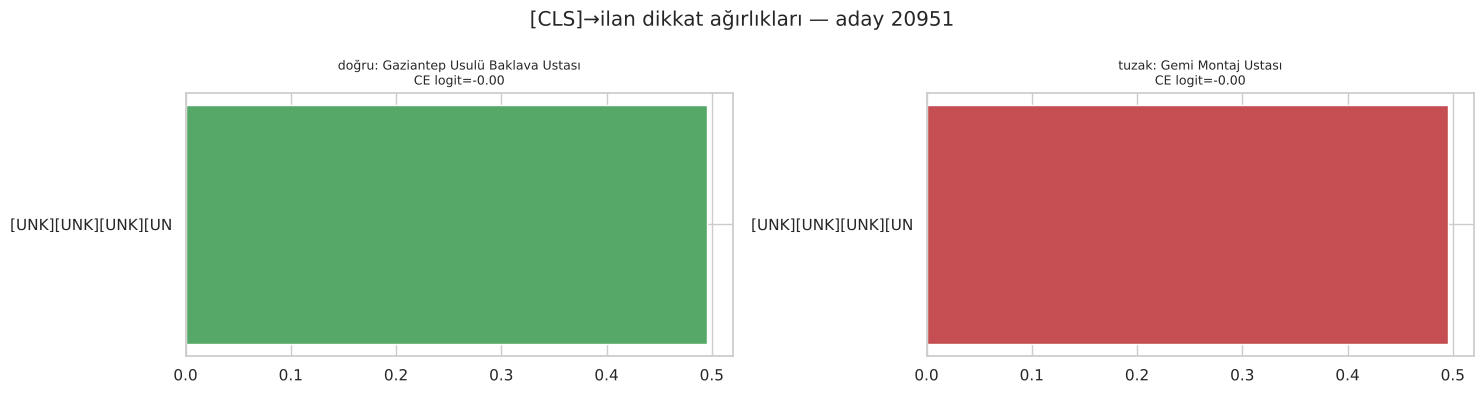

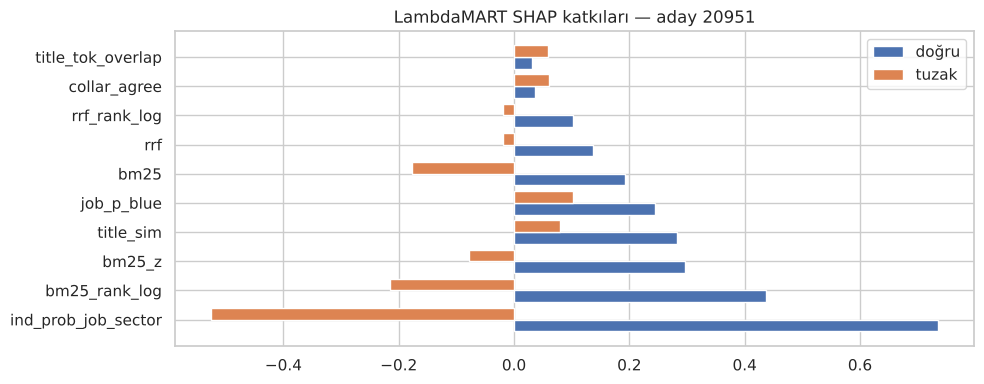

In [25]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
ce_dir = os.path.join(CFG["OUT_DIR"], "cross_encoder_best")
att_tok = AutoTokenizer.from_pretrained(ce_dir)
att_model = AutoModelForSequenceClassification.from_pretrained(ce_dir, attn_implementation="eager").to(DEVICE).eval()

@torch.no_grad()
def cls_attention(cv_txt, job_txt, top=12):
    enc = att_tok(cv_txt, job_txt, truncation=True, max_length=CFG["CE_MAX_LEN"], return_tensors="pt").to(DEVICE)
    out = att_model(**enc, output_attentions=True)
    att = out.attentions[-1][0].mean(0)[0].float().cpu().numpy()       # son katman, başlık ort., [CLS] satırı
    toks = att_tok.convert_ids_to_tokens(enc["input_ids"][0])
    seq = enc.token_type_ids[0].cpu().numpy() if "token_type_ids" in enc else None
    # ikinci segment (ilan) belirteçleri
    sep = [i for i, t in enumerate(toks) if t in (att_tok.sep_token, "</s>")]
    start = (sep[0] + 1) if sep else 0
    words, cur, w = [], "", 0.0
    for t, a in zip(toks[start:], att[start:]):
        if t in (att_tok.sep_token, att_tok.pad_token, "</s>", "<s>", att_tok.cls_token): continue
        if t.startswith("##"): cur += t[2:]; w += a
        elif t.startswith("▁") or not cur:
            if cur: words.append((cur, w))
            cur, w = t.lstrip("▁"), a
        else: cur += t; w += a
    if cur: words.append((cur, w))
    agg = defaultdict(float)
    for x, a in words:
        if len(x) > 1: agg[x] += a
    return sorted(agg.items(), key=lambda z: -z[1])[:top], float(out.logits.float().squeeze())

def pick_job(q, ranked, min_grade):
    for j in ranked[q]:
        if grade(q, j) >= min_grade:
            return int(j)
    return None

for si, q in enumerate(SHOWCASE[:2] if not DRY_RUN else SHOWCASE[:1]):
    good = pick_job(q, FULL_RANKED, 2)
    if good is None:      # (0 numaralı ilan da geçerli bir indekstir; 'or' kullanılmaz)
        good = int(max(QRELS[q].items(), key=lambda kv: kv[1])[0]) if QRELS[q] else int(FULL_RANKED[q][0])
    sims = np.asarray((JT.title_mat @ TS_CV[si].T).todense()).ravel()
    trap = int([j for j in np.argsort(-sims) if grade(q, j) == 0 and j != good][0])
    i = pos_of[q]
    # Tuzak ilan aday listesinde yoksa (Aşama 1 onu zaten elediyse) karşılaştırma için listenin sonuna eklenir;
    # böylece CE ve LambdaMART skorları aynı bağlamda (aynı 50'lik liste) hesaplanır.
    cand_i = [int(j) for j in CAND["test"][i]]
    free = [k for k in range(len(cand_i) - 1, -1, -1) if cand_i[k] not in (good, trap)]
    for j in (good, trap):
        if j not in cand_i:
            cand_i[free.pop(0)] = int(j)
    fused, dr, br, rr = HYB["test"]
    rq = CV.loc[q]; qm = core.QueryMeta.from_text(rq.headline, rq.cv_text, ATTR, rq.cv_struct)
    ce_i = ce_score_matrix(CE, [q], np.array([cand_i]))[0]
    f_i = core.build_pair_features(qm, np.array(cand_i), JT, TSIM, S_DENSE["test"][i, cand_i], S_BM25["test"][i, cand_i],
                                   fused[i, cand_i], dr[i, cand_i], br[i, cand_i], rr[i, cand_i], ce_i)
    core.assert_no_gold_columns(f_i, "hata-analizi")
    ltr_i = RANKER.predict(f_i[FEATS].to_numpy(np.float32))
    row = []
    for name, j in (("doğru", good), ("tuzak", trap)):
        ci = cand_i.index(j)
        row.append({"çift": f"{name}: {jobs.title.iloc[j][:50]}", "grade": grade(q, j),
                    "B3 eski kosinüs": round(float(S_LEGACY[i, j]), 4), "zero-shot e5-small": round(float(S_ZS_SMALL[i, j]), 4),
                    "ours dense": round(float(S_DENSE['test'][i, j]), 4), "ours CE": round(float(ce_i[ci]), 3),
                    "ours LambdaMART": round(float(ltr_i[ci]), 3),
                    "Aşama-1 aday listesinde mi": j in set(int(x) for x in CAND["test"][i])})
    print(f"\nADAY {q}: {CV.loc[q, 'headline']}")
    t = pd.DataFrame(row); display(t)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    for k, (name, j) in enumerate((("doğru", good), ("tuzak", trap))):
        toks, logit = cls_attention(core.compact_cv_for_ce(CV.loc[q, "cv_struct"]), core.compact_job_for_ce(jobs.job_struct.iloc[j]))
        ax[k].barh([t_[0][:18] for t_ in toks][::-1], [t_[1] for t_ in toks][::-1], color="#55A868" if k == 0 else "#C44E52")
        ax[k].set_title(f"{name}: {jobs.title.iloc[j][:40]}\nCE logit={logit:+.2f}", fontsize=9)
    fig.suptitle(f"[CLS]→ilan dikkat ağırlıkları — aday {q}"); fig.tight_layout()
    fig.savefig(os.path.join(CFG["FIG_DIR"], f"attention_{q}.png"), dpi=120); plt.show()
    # LambdaMART SHAP katkıları (doğru vs tuzak)
    ci = [cand_i.index(good), cand_i.index(trap)]
    cc = RANKER.booster_.predict(f_i[FEATS].to_numpy(np.float32)[ci], pred_contrib=True)[:, :-1]
    top = np.argsort(-np.abs(cc).max(0))[:10]
    fig, ax = plt.subplots(figsize=(10, 4)); w = 0.4
    for k in range(2):
        ax.barh(np.arange(len(top)) + k * w, cc[k, top], w, label=["doğru", "tuzak"][k])
    ax.set_yticks(np.arange(len(top)) + w / 2); ax.set_yticklabels([FEATS[t] for t in top]); ax.legend()
    ax.set_title(f"LambdaMART SHAP katkıları — aday {q}"); fig.tight_layout()
    fig.savefig(os.path.join(CFG["FIG_DIR"], f"shap_{q}.png"), dpi=120); plt.show()
att_model = None; free_mem()

In [26]:
# Genel hata analizi: tam boru hattının Top-1 hataları
pqf = per_q(MAIN[-1])
fails = pqf[pqf.Top1 == 0].sort_values("NDCG@10").head(10)
rows = []
for q in fails.index:
    j = FULL_RANKED[q][0]; best_j = max(QRELS[q].items(), key=lambda kv: kv[1])[0]
    rows.append({"aday": CV.loc[q, "headline"][:40], "altın uzmanlık": CV.loc[q, "gold_specialty"][:30],
                 "Top-1 ilan": jobs.title.iloc[j][:40], "Top-1 grade": grade(q, j), "en iyi ilan": jobs.title.iloc[best_j][:40],
                 "NDCG@10": round(100 * fails.loc[q, "NDCG@10"], 1)})
t = pd.DataFrame(rows); display(t)
g1 = Counter(grade(q, FULL_RANKED[q][0]) for q in pqf.index)
b1 = Counter(grade(q, B3_RANKED[q][0]) for q in pqf.index)
print("Top-1 grade dağılımı — Bizim:", dict(sorted(g1.items())), "| Eski (B3):", dict(sorted(b1.items())))

,aday,altın uzmanlık,Top-1 ilan,Top-1 grade,en iyi ilan,NDCG@10
0,Pattern Maker,Modelist,Beden İşçisi / Fabrika Üretim Elemanı,0,Tekstil Pastal Kesim Elemanı (Cutter),11.1
1,Liman ve Konteyner Terminali Operasyon M,Liman Operasyon Müdürü,Konteyner Saha Reach Stacker (Dolu Elleç,0,Airport Operations Control (OCC) Manager,13.9
2,Cleanroom HVAC Architecture & Validation,Mekanik Tesisat Mühendisi,Linux Systems Engineer,0,Ar-Ge Tasarım Mühendisi (Simülasyon & Te,15.9
3,Müdür,İnsan Kaynakları Müdürü,İK Operasyon ve Sistem Uzmanı (SAP Succe,0,İnsan Kaynakları Yöneticisi,18.5
4,Alüminyum Alt Konstrüksiyon ve Giydirme,Cephe Tasarım Mühendisi,Mekanik Dış Cephe Kaplama Ustası (Serami,0,Endüstriyel Tesisler Şantiye Mühendisi,32.5
5,Fire Protection Systems Engineer,Yangın Söndürme Sistemleri Müh,Dynamic Weighing & Packaging Automation,1,Ar-Ge Tasarım Mühendisi (Simülasyon & Te,40.3
6,Veri ve Yapay Zeka Ürün Yöneticisi (AI /,Ürün Yöneticisi,Büyük Dil Modelleri ve NLP Araştırma Müh,1,BT Proje Yöneticisi,48.5
7,iOS Güvenlik & Kriptografi Mühendisi,Mobil Yazılım Geliştirici,Senior iOS & Mobile Security Engineer,1,iOS Geliştirici (Swift),48.7
8,Kurumsal İletişim ve Medya İlişkileri Mü,Kurumsal İletişim ve Halkla İl,Kurumsal İletişim Uzmanı,1,Kıdemli Kurumsal İletişim Müdürü,51.7


Top-1 grade dağılımı — Bizim: {0: 5, 1: 4, 2: 14, 3: 3} | Eski (B3): {0: 25, 1: 1}


## 13. Dışa aktarım: `export_model_bundle.zip`
Bi-encoder, cross-encoder, LambdaMART, öznitelik sınıflandırıcıları, FAISS indeksi, ilan tablosu, yapılandırma ve
`match_candidate_sota.py` tek pakette. Ağırlıklar `EXPORT_HALF=True` ile fp16 kaydedilir (≈2,3 GB yerine ≈1,2 GB'lık
model başına yarı boyut); çıkarımda fp32'ye yükseltilir. Paket Drive'a yedeklenir; tarayıcı indirmesi yalnız küçük
paketlerde otomatik başlatılır. Son hücre paketi sıfırdan yükleyip **notebook sonuçlarıyla eşitliğini** ölçer.

In [27]:
import joblib
EX = CFG["EXPORT_DIR"]
if os.path.isdir(EX): shutil.rmtree(EX)
os.makedirs(EX)
def save_model(m, path, half):
    if half:
        m.half(); m.save(path); m.float()
    else:
        m.save(path)
save_model(BI, os.path.join(EX, "bi_encoder"), CFG["EXPORT_HALF"])
save_model(CE, os.path.join(EX, "cross_encoder"), CFG["EXPORT_HALF"])
# Çıkarımdaki sorgu tarafı paketteki (fp16'ya yuvarlanmış) ağırlıklarla kodlanır; ilan vektörleri de AYNI ağırlıklarla
# yeniden kodlanır (belge/sorgu tarafı aynı hassasiyette)
E_jobs_export = encode(BI, job_texts(DP)) if CFG["EXPORT_HALF"] else E_jobs
RANKER.booster_.save_model(os.path.join(EX, "lambdamart.txt"))
joblib.dump(ATTR, os.path.join(EX, "attribute_models.joblib"))
joblib.dump(TSIM, os.path.join(EX, "title_sim.joblib"))
jobs.drop(columns=[c for c in jobs.columns if c.startswith("gold_") or c.startswith("legacy_")]).to_parquet(os.path.join(EX, "jobs.parquet"), index=False)
cvs[["cv_id", "headline", "cv_text", "split", "source"]].to_parquet(os.path.join(EX, "clean_cvs.parquet"), index=False)
np.save(os.path.join(EX, "job_embeddings.npy"), E_jobs_export)
import faiss
index = faiss.IndexFlatIP(E_jobs_export.shape[1]); index.add(E_jobs_export.astype(np.float32)); faiss.write_index(index, os.path.join(EX, "faiss.index"))
shutil.copy(os.path.join(CFG["DATA_DIR"], "match_candidate_sota.py"), os.path.join(EX, "match_candidate_sota.py"))
EXPORT_CFG = {"bi_encoder_base": CFG["BI_ENCODER_BASE"], "cross_encoder_base": CFG["CROSS_ENCODER_BASE"],
              "query_prefix": QP, "doc_prefix": DP, "rrf_k": CFG["RRF_K"], "n_candidates": CFG["N_CANDIDATES"],
              "mnrl_scale": best_scale, "feature_columns": FEATS, "ltr_params": LTR_BEST, "ltr_n_estimators": int(n_est),
              "ref_year": core.REF_YEAR, "max_seq_len": CFG["MAX_SEQ_LEN"], "ce_max_len": CFG["CE_MAX_LEN"],
              "export_half": CFG["EXPORT_HALF"], "sklearn_version": sklearn.__version__,
              "rel_threshold": CFG["REL_THRESHOLD"], "dry_run": DRY_RUN, "core_version": core.__version__}
json.dump(EXPORT_CFG, open(os.path.join(EX, "config.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)
METRICS = {"ablation_test": ABL.reset_index().to_dict(orient="records"), "cold_start_test": COLD_TBL.reset_index().to_dict(orient="records"),
           "ablation_component_tests": COMP.reset_index().to_dict(orient="records"),
           "temperature_sweep": {str(k): v for k, v in temp_res.items()}, "ltr_cv_ndcg10": study.best_value}
json.dump(METRICS, open(os.path.join(EX, "metrics.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=str)
ABL.to_csv(os.path.join(EX, "ablation_test.csv")); COLD_TBL.to_csv(os.path.join(EX, "cold_start_test.csv"))
COMP.to_csv(os.path.join(EX, "ablation_component_tests.csv"))
for f in os.listdir(CFG["FIG_DIR"]):
    os.makedirs(os.path.join(EX, "figures"), exist_ok=True); shutil.copy(os.path.join(CFG["FIG_DIR"], f), os.path.join(EX, "figures", f))
open(os.path.join(EX, "README_INFERENCE.md"), "w", encoding="utf-8").write(
    "# export_model_bundle\n\n```bash\n"
    f"pip install sentence-transformers==6.1.0 transformers==5.17.0 lightgbm==4.7.0 faiss-cpu scikit-learn=={sklearn.__version__} pandas pyarrow joblib\n"
    "python match_candidate_sota.py --bundle . --cv-id 20951\npython match_candidate_sota.py --bundle . --cv-file aday.txt --headline 'Baklava Ustası'\n"
    "pip install fastapi uvicorn && python match_candidate_sota.py --bundle . --serve   # POST /match {cv_text, headline, top_k}\n```\n")
# ZIP_STORED: ağırlıklar zaten sıkıştırılamaz; DEFLATE dakikalar sürer ve ~%7 kazandırır
zp = os.path.join(CFG["WORK_DIR"], "export_model_bundle.zip")
with zipfile.ZipFile(zp, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as z:
    for root, _, fs in os.walk(EX):
        for f in fs:
            if "__pycache__" in root: continue
            full = os.path.join(root, f); z.write(full, arcname=os.path.relpath(full, CFG["WORK_DIR"]))
print("Paket:", zp, f"({os.path.getsize(zp) / 1e9:.2f} GB)")
if DRIVE_DIR:
    shutil.copy(zp, os.path.join(DRIVE_DIR, "export_model_bundle.zip"))
    shutil.copytree(CFG["FIG_DIR"], os.path.join(DRIVE_DIR, "figures"), dirs_exist_ok=True)
    for f in ("ablation_test.csv", "ablation_component_tests.csv", "cold_start_test.csv", "stage1_training_log.csv",
              "stage2a_training_log.csv"):
        if os.path.exists(os.path.join(CFG["OUT_DIR"], f)): shutil.copy(os.path.join(CFG["OUT_DIR"], f), DRIVE_DIR)
    # Drive yazmaları arka planda yüklenir; büyük paketin oturum kapanmadan Drive'a ulaşmasını garanti et
    try:
        from google.colab import drive
        drive.flush_and_unmount()
        print("Drive yedeği senkronize edildi:", DRIVE_DIR)
    except Exception as e:
        print("Drive senkronizasyonu doğrulanamadı; oturumu kapatmadan önce Drive'da dosyayı kontrol edin:", e)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 550.80it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 687.48it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

...

Batches:  81%|████████  | 38/47 [00:02<00:00, 19.86it/s]

Batches:  87%|████████▋ | 41/47 [00:02<00:00, 21.37it/s]

Batches:  94%|█████████▎| 44/47 [00:02<00:00, 22.25it/s]

Batches: 100%|██████████| 47/47 [00:02<00:00, 19.01it/s]

Paket: /home/user/umidovski/work/dry_run/export_model_bundle.zip (0.02 GB)


In [28]:
# Duman testi + PARİTE: paketi sıfırdan yükle (notebook nesneleri KULLANILMAZ), notebook'un test sıralamalarıyla karşılaştır
sys.path.insert(0, CFG["EXPORT_DIR"])
import match_candidate_sota as mcs
importlib.reload(mcs)
matcher = mcs.SOTAMatcher.load(CFG["EXPORT_DIR"], device=DEVICE)
q = SHOWCASE[0] if SHOWCASE else TEST_IDS[0]
res = matcher.match(CV.loc[q, "cv_text"], CV.loc[q, "headline"], top_k=10)
print(f"Aday {q}: {CV.loc[q, 'headline']}")
display(res)
assert len(res) == 10
par_q = (SHOWCASE + [x for x in TEST_IDS if x not in SHOWCASE])[: 8 if DRY_RUN else 30]
ov, t1 = [], []
for qq in par_q:
    r_ = matcher.match(CV.loc[qq, "cv_text"], CV.loc[qq, "headline"], top_k=10)
    got = [JIDX[k] for k in r_.job_key]
    ov.append(len(set(got) & set(FULL_RANKED[qq][:10])) / 10.0); t1.append(got[0] == FULL_RANKED[qq][0])
print(f"Paket ↔ notebook paritesi ({len(par_q)} test sorgusu): ortalama Top-10 örtüşme = %{100*np.mean(ov):.1f}, "
      f"Top-1 aynı = %{100*np.mean(t1):.1f}  (fp16 ağırlık yuvarlaması küçük farklar yaratabilir)")
try:
    from fastapi.testclient import TestClient
    client = TestClient(mcs.build_app(matcher))
    resp = client.post("/match", json={"cv_text": CV.loc[q, "cv_text"], "headline": CV.loc[q, "headline"], "top_k": 3})
    print("FastAPI POST /match ->", resp.status_code, [x["title"] for x in resp.json()] if resp.status_code == 200 else resp.text[:200])
except ImportError:
    print("fastapi/httpx kurulu değil: API duman testi atlandı (pip install fastapi httpx).")
zsize = os.path.getsize(os.path.join(CFG["WORK_DIR"], "export_model_bundle.zip"))
if IN_COLAB:
    if zsize < 1.5e9:
        try:
            from google.colab import files
            files.download(os.path.join(CFG["WORK_DIR"], "export_model_bundle.zip"))
        except Exception as e:
            print("İndirme başlatılamadı (Dosyalar panelinden indirebilirsiniz):", e)
    else:
        print(f"Paket {zsize/1e9:.1f} GB: tarayıcı indirmesi güvenilir değil. Drive'dan indirin:",
              DRIVE_DIR or "(Drive bağlı değil: sol menü > Dosyalar > export_model_bundle.zip > İndir)")

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 2352.42it/s]

Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 3370.31it/s]

Aday 20951: Gaziantep Baklava & Yufka Ustası


,rank,job_key,title,company,industry,position_level,mode,city,score,dense_cos,bm25,ce_score,ind_prob,collar_agree,sen_diff,loc_ok,top_factors
0,1,J0914,Gaziantep Usulü Baklava Ustası,Marmara Teknik Tesisat ve Bakım Ltd.,CHEF_HORECA,SENIOR,OnSite,Hatay,1.401812,0.999782,380.473572,-0.002864,0.701510,0.994611,0.0,0.0,ind_prob_job_sector=+0.73; bm25_rank_log=+0.44; bm25_z=+0.30
1,2,J0827,Taş Fırın ve Ekmek Pişirme Ustası,Sivas Chef ve İmalat San. Ltd.,CHEF_HORECA,SENIOR,OnSite,Kocaeli,1.376042,0.999388,86.905876,-0.002873,0.701510,0.983622,0.0,0.0,ind_prob_job_sector=+0.83; bm25_rank_log=+0.34; dense_z=+0.22
2,3,J0821,Geleneksel Şerbetli Tatlı Ustası,Pancar Chef ve İmalat San. Ltd.,CHEF_HORECA,SENIOR,OnSite,İzmir,1.344714,0.999165,78.288658,-0.002876,0.701510,0.977221,0.0,0.0,ind_prob_job_sector=+0.83; job_desc_len_log=+0.26; dense_z=+0.24
3,4,J0211,Taş Fırın Pide ve Lahmacun Ustası,Demirtaş Chef ve İmalat San. Ltd.,CHEF_HORECA,SENIOR,OnSite,Bursa,1.344714,0.999263,68.168518,-0.002873,0.701510,0.903757,0.0,0.0,ind_prob_job_sector=+0.86; dense_z=+0.28; job_desc_len_log=+0.23
4,5,J0262,Kol Böreği ve Boşnak Böreği Ustası,Tarsus Endüstriyel Teknik Hizmetler A.Ş.,CHEF_HORECA,SENIOR,OnSite,Mersin,1.230973,0.999792,113.749100,-0.002864,0.701510,0.948491,0.0,0.0,ind_prob_job_sector=+0.75; bm25_rank_log=+0.41; job_p_blue=+0.28
5,6,J2323,Taş Fırın Pide ve Lahmacun Ustası,Develi Kebap Restoranları,CHEF_HORECA,MID,OnSite,İstanbul,1.229484,0.999809,114.137878,-0.002864,0.701510,0.903757,-1.0,0.0,ind_prob_job_sector=+0.71; bm25_rank_log=+0.41; rrf=+0.28
6,7,J1162,Taş Fırın Simit Ustası,Ereğli Metal ve Kalıp Fabrikası,CHEF_HORECA,SENIOR,OnSite,Ankara,1.229484,0.999783,117.675545,-0.002864,0.701510,0.991961,0.0,1.0,ind_prob_job_sector=+0.74; bm25_rank_log=+0.41; bm25_z=+0.28
7,8,J1125,Pide ve Lahmacun Ustası,GÜLLÜOĞLU SOFRASI,CHEF_HORECA,SPECIALIST,OnSite,Ankara,0.521968,0.999943,80.138893,-0.002864,0.701510,0.934093,-1.0,1.0,ind_prob_job_sector=+0.66; bm25_rank_log=+0.33; rrf=+0.21
8,9,J1174,Unlu Mamuller ve Fırın Ustası (Baker),Marmara Teknik Tesisat ve Bakım Ltd.,CHEF_HORECA,SENIOR,OnSite,Hatay,0.257709,0.999825,77.041603,-0.002864,0.701510,0.873845,0.0,0.0,ind_prob_job_sector=+0.70; job_p_blue=+0.22; bm25_rank_log=+0.20
9,10,J0758,Mermer Kesim ve Montaj Ustası,Öz İzmir Saha ve Lojistik Hizmetleri,CONSTRUCTION,SENIOR,OnSite,İzmir,0.101299,0.999788,46.971882,-0.002864,0.085367,0.967315,0.0,0.0,ind_prob_job_sector=+0.62; job_p_blue=+0.25; title_sim=+0.13


Paket ↔ notebook paritesi (8 test sorgusu): ortalama Top-10 örtüşme = %98.8, Top-1 aynı = %100.0  (fp16 ağırlık yuvarlaması küçük farklar yaratabilir)


FastAPI POST /match -> 200 ['Gaziantep Usulü Baklava Ustası', 'Taş Fırın ve Ekmek Pişirme Ustası', 'Geleneksel Şerbetli Tatlı Ustası']


## 14. Özet

In [29]:
print("ANA ABLATION (test, sızıntısız, kademeli qrels):")
print(ABL.loc[MAIN, ["NDCG@10", "MRR@10", "P@10", "P@10_capped", "R@10", "Top1", "NDCG@10 %95 GA"]].to_string())
print("\nNot: Hedefler (Top-1>88, NDCG@10>92, P@10>85) yukarıda dürüstçe karşılaştırılmıştır. P@10, alakalı ilan sayısı"
      " 10'dan az olan sorgularda yapısal olarak 1'e ulaşamaz; bu yüzden P@10_capped de raporlanır.")
json.dump({"done": True, "dry_run": DRY_RUN}, open(os.path.join(CFG["OUT_DIR"], "RUN_OK.json"), "w"))

ANA ABLATION (test, sızıntısız, kademeli qrels):
                                         NDCG@10  MRR@10   P@10  P@10_capped   R@10   Top1 NDCG@10 %95 GA
Sistem                                                                                                   
B1: BM25                                   57.30   84.94  51.15        58.44  26.32  76.92   [48.7, 66.0]
B2: Zero-shot e5-small                      3.04    6.16   2.69         2.69   0.25   0.00     [1.6, 4.7]
B3: Eski (e5-small + CosineSimLoss)         1.81    1.36   1.15         1.15   0.07   0.00     [0.7, 3.3]
S1: Fine-tuned bi-encoder + BM25 (RRF)     33.29   53.52  31.15        36.16  16.95  34.62   [26.3, 40.8]
S2: Hybrid + Cross-encoder + LambdaMART    58.17   75.51  50.38        56.65  25.05  65.38   [48.3, 68.4]

Not: Hedefler (Top-1>88, NDCG@10>92, P@10>85) yukarıda dürüstçe karşılaştırılmıştır. P@10, alakalı ilan sayısı 10'dan az olan sorgularda yapısal olarak 1'e ulaşamaz; bu yüzden P@10_capped de raporlanır.
